# Imports

In [1]:
import numpy as np
import random
from scipy import stats
from collections import defaultdict
import matplotlib.pyplot as plt
from itertools import combinations
from statsmodels.stats.multitest import multipletests
import pandas as pd

In [24]:
import sys, numpy, scipy, matplotlib, statsmodels, pandas
print(sys.version); print(numpy.__version__, scipy.__version__, matplotlib.__version__, statsmodels.__version__, pandas.__version__)

3.14.4 (tags/v3.14.4:23116f9, Apr  7 2026, 14:10:54) [MSC v.1944 64 bit (AMD64)]
2.4.4 1.17.1 3.10.8 0.15.0 3.0.2


# Constants

In [ ]:
NUM_AGENTS = 10
NUM_ACTIONS = 5
HORIZON = 100
N_TRIALS = 100
MAX_REWARD_ABS_VAL = 10.0
MIN_Z_I = 80
MAX_Z_I = 150
MIN_P_I = 0.2
MAX_P_I = 0.8

BASE_SEED = 0

# Policies

In [4]:
class EpsilonGreedy:
    def __init__(self, epsilon, num_actions, name="Epsilon Greedy"):
        self.name = name
        self.epsilon = epsilon
        self.q = {a: 0.0 for a in range(num_actions)}
        self.n = {a: 0 for a in range(num_actions)}

    def update(self, a, r):
        self.n[a] += 1
        self.q[a] += (r - self.q[a]) / self.n[a]

    def select(self, active_actions):
        if self.rng.random() < self.epsilon:
            return int(self.rng.choice(active_actions))

        best_value = max(self.q[a] for a in active_actions)
        best = [a for a in active_actions if self.q[a] == best_value]
        return int(self.rng.choice(best))


class Boltzmann:
    def __init__(self, temperature, num_actions, name="Boltzmann"):
        self.name = name
        self.temperature = temperature
        self.q = {a: 0.0 for a in range(num_actions)}
        self.n = {a: 0 for a in range(num_actions)}

    def update(self, a, r):
        self.n[a] += 1
        self.q[a] += (r - self.q[a]) / self.n[a]

    def select(self, active_actions):
        q_values = np.array([self.q[a] for a in active_actions])
        logits = (q_values - np.max(q_values)) / self.temperature

        exp_q = np.exp(logits)
        probabilities = exp_q / np.sum(exp_q)

        return int(self.rng.choice(active_actions, p=probabilities))


class UCB:
    def __init__(self, c, num_actions, name="UCB"):
        self.name = name
        self.c = c
        self.q = {a: 0.0 for a in range(num_actions)}
        self.n = {a: 0 for a in range(num_actions)}
        self.t = 0

    def update(self, a, r):
        self.n[a] += 1
        self.q[a] += (r - self.q[a]) / self.n[a]

    def select(self, active_actions):
        self.t += 1
        unvisited = [a for a in active_actions if self.n[a] == 0]

        if unvisited:
            return int(self.rng.choice(unvisited))

        ucb_values = {
            a: self.q[a] + self.c * np.sqrt(np.log(self.t) / self.n[a])
            for a in active_actions
        }

        best_value = max(ucb_values.values())
        best = [a for a in active_actions if ucb_values[a] == best_value]
        return int(self.rng.choice(best))


class Thompson:
    def __init__(self, num_actions, name="Thompson Policy"):
        self.name = name
        self.q = {a: 0.0 for a in range(num_actions)}
        self.n = {a: 0 for a in range(num_actions)}
        self.m2 = {a: 0.0 for a in range(num_actions)}

    def update(self, a, r):
        n = self.n[a] + 1
        old_mean = self.q[a]
        new_mean = old_mean + (r - old_mean) / n

        self.m2[a] += (r - old_mean) * (r - new_mean)

        self.q[a] = new_mean
        self.n[a] = n

    def select(self, active_actions):
        samples = []
        for a in active_actions:
            if self.n[a] < 2:
                std = 1.0
            else:
                std = np.sqrt(self.m2[a] / (self.n[a] - 1) / self.n[a])
                std = max(std, 1e-6)

            samples.append(self.rng.normal(self.q[a], std))

        return int(active_actions[np.argmax(samples)])


class GradientBandit:
    def __init__(self, alpha, num_actions, name="Gradient Bandit"):
        self.name = name
        self.alpha = alpha

        self.h = {a: 0.0 for a in range(num_actions)}
        self.reward_sum = {a: 0.0 for a in range(num_actions)}
        self.reward_count = {a: 0 for a in range(num_actions)}

        self.avg_r = 0.0
        self.active_actions = []
        self.probabilities = {}

    def update(self, a, r, active_actions):
        self.reward_sum[a] += r
        self.reward_count[a] += 1

        total_sum = sum(self.reward_sum[x] for x in active_actions)
        total_count = sum(self.reward_count[x] for x in active_actions)

        self.avg_r = total_sum / total_count if total_count else 0.0
        for action in active_actions:
            if action == a:
                self.h[action] += (
                    self.alpha * (r - self.avg_r)
                    * (1 - self.probabilities[action])
                )
            else:
                self.h[action] -= (
                    self.alpha * (r - self.avg_r)
                    * self.probabilities[action]
                )

    def select(self, active_actions):
        self.active_actions = list(active_actions)

        logits = np.array([self.h[a] for a in active_actions])
        logits -= np.max(logits)

        exp_h = np.exp(logits)
        probs = exp_h / np.sum(exp_h)

        self.probabilities = dict(zip(active_actions, probs))

        return int(self.rng.choice(active_actions, p=probs))

For each algorithm, I implemented three main methods:
`__init__`, `update`, and `select`.

The `__init__` method initializes the algorithm's internal
parameters, including its name and any required hyperparameters.

The `update` method receives the selected action and its observed
reward, allowing the algorithm to update its estimates or internal
parameters based on the new observation.

The `select` method chooses an action from the set of currently
active actions according to the algorithm's selection policy.

Each agent maintains its own learning state and does not share
observations or learned information with other agents.

To make the algorithms compatible with action deactivation, I
restricted the action-selection process to the currently active
actions.

The existing estimates of inactive actions are retained, but
inactive actions are excluded from future selection decisions.

For the Gradient Bandit algorithm, I additionally modified the
baseline calculation to consider only observations associated
with actions that were active at the beginning of the current
decision step.

To implement this modification, I maintain the cumulative reward
and selection count separately for each action and compute the average reward of only the active actions.

# Environment

In [5]:
class Environment:
    def __init__(self, rng, num_actions):
        self.rng = rng
        self.r_max_i = rng.uniform(0, MAX_REWARD_ABS_VAL, num_actions)
        self.r_min_i = rng.uniform(-MAX_REWARD_ABS_VAL, 0, num_actions)
        self.p_i = rng.uniform(MIN_P_I, MAX_P_I, num_actions)
        self.z_i = rng.integers(MIN_Z_I, MAX_Z_I+1, num_actions)
        self.w_i = self.z_i * self.r_max_i 
        self.active = np.ones(num_actions, dtype=bool)

    def step(self, action):
        success = self.rng.random() < self.p_i[action]
        reward = self.r_max_i[action] if success else self.r_min_i[action]
        if reward > 0:
            self.z_i[action] -= 1
            self.w_i[action] -= self.r_max_i[action]
            if self.z_i[action] <= 0:
                self.active[action] = False
        return reward

# Agent

In [6]:
class Agent:
    def __init__(self, num_actions, policy, rng):
        self.num_actions = num_actions
        self.policy = policy
        self.policy.rng = rng

    def select(self, active):
        return self.policy.select(active)

    def update(self, a, r, active):
        if isinstance(self.policy, GradientBandit):
            self.policy.update(a, r, active)
        else:
            self.policy.update(a, r)

# Experiment

In [7]:
def run_trial(num_actions, policies, L, seed):
    algo_names = list(dict.fromkeys(policy.name for policy in policies))
    algo_counts = {
        name: sum(1 for p in policies if p.name == name)
        for name in algo_names
    }

    ss = np.random.SeedSequence(seed)
    env_seed, order_seed, agent_seed = ss.spawn(3)
    env_rng = np.random.default_rng(env_seed)
    order_rng = np.random.default_rng(order_seed)
    agent_seeds = np.random.default_rng(agent_seed).spawn(len(policies))

    env = Environment(env_rng, num_actions)
    agents = [
        Agent(num_actions, policy, np.random.default_rng(agent_seeds[i]))
        for i, policy in enumerate(policies)
    ]

    r_round = np.zeros(L)
    cum_population = np.zeros(L)
    cum_agent = np.zeros((len(agents), L))
    cum_algo = {name: np.zeros(L) for name in algo_names}
    n_active = np.zeros(L)
    remaining_z = np.zeros((L+1, num_actions))
    remaining_z[0] = env.z_i
    pull_counts  = np.zeros((L, num_actions), dtype=int)

    running_person = np.zeros(len(agents))
    running_algo = {name: 0.0 for name in algo_names}

    for t in range(L):
        order = order_rng.permutation(len(agents))
        rewards = np.zeros(len(agents))

        for idx in order:
            agent = agents[idx]
            active_actions = np.where(env.active)[0]

            if len(active_actions) == 0:
                break

            action = agent.select(active_actions)
            reward = env.step(action)
            agent.update(action, reward, active_actions)

            pull_counts[t, action] += 1
            rewards[idx] = reward
            running_person[idx] += reward
            running_algo[policies[idx].name] += reward

        r_round[t] = rewards.mean()
        cum_agent[:, t] = running_person

        for name in algo_names:
            cum_algo[name][t] = running_algo[name] / algo_counts[name]

        cum_population[t] = running_person.sum()
        n_active[t] = np.sum(env.active)
        remaining_z[t+1] = env.z_i

    return {
        "r_round":        r_round,
        "cum_population": cum_population,
        "cum_agent":      cum_agent,
        "cum_algo":       cum_algo,
        "n_active":       n_active,
        "remaining_z":    remaining_z,
        "action_value":   env.p_i * env.r_max_i + (1-env.p_i) * env.r_min_i,
        "pull_counts":  pull_counts,
    }

Each independent simulation run starts with a newly initialized
environment, including freshly sampled reward parameters and
action capacities.

The internal states of all agents and learning algorithms are
also reset at the beginning of every run.

Within each round, the order in which agents make their
selections is randomized to avoid systematic advantages
associated with a fixed selection order.

All stochastic components use explicitly controlled random
seeds to ensure reproducibility. Different independent
simulation runs use distinct random seeds so that their
random outcomes are not identical.

In [8]:
def mean_ci(arr_2d, confidence=0.95):
    n_trials = arr_2d.shape[0]
    m = arr_2d.mean(axis=0)
    se = arr_2d.std(axis=0, ddof=1) / np.sqrt(n_trials)
    h = se * stats.t.ppf((1 + confidence) / 2, n_trials - 1)
    return m, h

def plot_mean_ci(x, mean, half_width, title, label=None, ax=None, alpha=0.2, ylim=None):
    ax = ax or plt.gca()
    ax.plot(x, mean, label=label)
    ax.fill_between(x, mean - half_width, mean + half_width, alpha=alpha)
    ax.set_xlabel("Round"); ax.set_ylabel(title); ax.set_title(title+" per Round")
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.grid(alpha=0.3)

For each evaluation metric, I calculate the sample mean across
independent simulation runs and report its 95% confidence interval.

I use the Student's t-distribution because the population standard
deviation is unknown and must be estimated from the sample.

For a metric observed across $N$ independent trials, the sample
mean and confidence interval half-width are:

$$
\bar{x} = \frac{1}{N}\sum_{j=1}^{N}x_j
$$

$$
h = t_{N-1,\,0.975}
\frac{s}{\sqrt{N}}
$$

where $s$ is the sample standard deviation and
$t_{N-1,\,0.975}$ is the 97.5th percentile of the Student's
t-distribution with $N-1$ degrees of freedom.

The resulting 95% confidence interval is:

$$
[\bar{x}-h,\ \bar{x}+h]
$$

The independent statistical unit is one complete simulation run.
Therefore, confidence intervals are calculated across independent
runs rather than across agents or individual rounds.

For sufficiently large sample sizes, the Central Limit Theorem
supports an approximately normal sampling distribution of the
sample mean.

# Hyperparameter Selection

In [9]:
reward = {}
TUNING_SEED_BASE = 10_000_000
for eps in np.linspace(0.01, 1.0, 100):
    policy = lambda: (EpsilonGreedy(epsilon=eps, num_actions=NUM_ACTIONS),)
    results = [run_trial(NUM_ACTIONS, policy(), HORIZON, seed+TUNING_SEED_BASE) for seed in range(5)]

    final_rewards = np.array([r["cum_agent"][0, -1] for r in results])
    reward[eps] = final_rewards.mean()

eps = float(max(reward, key=reward.get))
eps

0.09999999999999999

In [10]:
reward = {}
for tau in np.linspace(0.01, 3.0, 100):
    policy = lambda: (Boltzmann(temperature=tau, num_actions=NUM_ACTIONS),)
    results = [run_trial(NUM_ACTIONS, policy(), HORIZON, seed+TUNING_SEED_BASE) for seed in range(5)]

    final_rewards = np.array([r["cum_agent"][0, -1] for r in results])
    reward[tau] = final_rewards.mean()

tau = float(max(reward, key=reward.get))
tau

0.13080808080808082

In [11]:
reward = {}
for alpha in np.linspace(0.01, 1.0, 100):
    policy = lambda: (GradientBandit(alpha=alpha, num_actions=NUM_ACTIONS),)
    results = [run_trial(NUM_ACTIONS, policy(), HORIZON, seed+TUNING_SEED_BASE) for seed in range(5)]

    final_rewards = np.array([r["cum_agent"][0, -1] for r in results])
    reward[alpha] = final_rewards.mean()
    
alpha = float(max(reward, key=reward.get))
alpha

0.19

The hyperparameters of the Epsilon-Greedy, Boltzmann, and
Gradient Bandit algorithms were selected through preliminary
experiments.

For each algorithm, I evaluated 100 candidate hyperparameter
values. Each candidate was evaluated over five independent
simulation runs, and the candidate with the highest mean final
cumulative reward was selected.

These preliminary experiments were conducted separately from
the final evaluation experiments, using distinct random seeds.
The selected hyperparameters were fixed before the final
experiments and were not modified based on the final evaluation
results.

This separation prevents the final evaluation results from
influencing hyperparameter selection, avoiding evaluation
leakage and overly optimistic performance estimates.

The final experiments therefore provide an independent
evaluation of the algorithms under the selected settings.

Although the hyperparameters selected in a single-agent
setting are not necessarily optimal in a heterogeneous or
homogeneous multi-agent population, this approach reduces
the computational cost of hyperparameter selection. This
limitation should be considered when interpreting the results.

# A) Heterogeneous Population

In this part, we implement a population of 10 agents. Each of the five bandit algorithms is assigned to exactly two agents:

- Epsilon-Greedy
- Boltzmann (Softmax)
- Upper Confidence Bound (UCB)
- Thompson Sampling
- Gradient Bandit

All agents interact with the same environment and therefore compete for the same limited action capacities. However, each agent maintains its own learning state and selects actions independently.

At the beginning of each round, the order in which agents make their selections is randomized. This prevents the order of agent assignments from systematically favoring any particular algorithm.

We perform 100 independent simulation runs. Each run uses a different random seed, and the policy instances are reinitialized between runs.

In [ ]:
def run_trials(policy_factories, n_trials, horizon, num_actions, W=10):
    results = []
    for seed in range(n_trials):
        results.append(
            run_trial(
                num_actions,
                [f() for f in policy_factories],
                horizon,
                seed+BASE_SEED
            )
        )

    algo_names = list(results[0]["cum_algo"].keys())
    order = np.argsort(
        -np.stack([r["action_value"] for r in results]),
        axis=1
    )

    remaining_z = np.stack([r["remaining_z"] for r in results])
    remaining_z_sorted = np.take_along_axis(
        remaining_z,
        order[:, None, :],
        axis=2
    )

    pull_counts = np.stack([r["pull_counts"] for r in results])
    pulls_sorted = np.take_along_axis(
        pull_counts,
        order[:, None, :],
        axis=2
    )

    cumsum = np.cumsum(pulls_sorted, axis=1)
    window = cumsum.copy()
    window[:, W:, :] -= cumsum[:, :-W, :]

    agents = results[0]["cum_agent"].shape[0]
    rounds_so_far = np.minimum(np.arange(1, horizon + 1), W)
    denom = agents * rounds_so_far

    window_frac = window / denom[None, :, None]

    return {
        "algo_names": algo_names,

        "r_round": mean_ci(
            np.stack([r["r_round"] for r in results])
        ),
        "n_active": mean_ci(
            np.stack([r["n_active"] for r in results])
        ),
        "cum_population": mean_ci(
            np.stack([r["cum_population"] for r in results])
        ),
        "cum_agent": mean_ci(
            np.stack([r["cum_agent"] for r in results])
        ),
        "cum_algo": {
            name: mean_ci(
                np.stack([r["cum_algo"][name] for r in results])
            )
            for name in algo_names
        },
        "raw_cum_algo": {
            name: np.stack([r["cum_algo"][name] for r in results])
            for name in algo_names
        },
        "remaining_z": mean_ci(remaining_z_sorted),
        "window_frac": mean_ci(window_frac),
        "W": W,
    }

In [13]:
def report_results(res, num_actions):
    horizon = len(res["n_active"][0])
    rounds = np.arange(1, horizon + 1)
    rounds_snap = np.arange(0, horizon + 1)

    for key, title, ylim in [
        ("r_round", "Average Reward", None),
        ("n_active", "Number of Active Actions", (0, num_actions * 1.1)),
        ("cum_population", "Cumulative Reward of Population", None),
    ]:
        fig, ax = plt.subplots(figsize=(9, 6))
        plot_mean_ci(
            rounds, *res[key], title, ax=ax, ylim=ylim
        )
        fig.tight_layout()
        plt.show()

    plots = []
    if len(res["algo_names"]) > 1:
        plots.append((res["cum_algo"], rounds, "Cumulative Reward per Agent"))
    plots.extend([
        (res["remaining_z"], rounds_snap, r"Remaining success budget $z_i$"),
        (res["window_frac"], rounds, f"Pull share over last {res['W']} rounds"),
    ])
    for i, (data, x, title) in enumerate(plots):
        fig, ax = plt.subplots(figsize=(9, 6))
        if i == 0 and len(plots)>2:
            for name in res["algo_names"]:
                plot_mean_ci(
                    x, *data[name], title,
                    label=name, ax=ax, alpha=0.1
                )
        else:
            for r in range(num_actions):
                plot_mean_ci(
                    x,
                    data[0][:, r],
                    data[1][:, r],
                    title,
                    label=f"Rank {r + 1}",
                    ax=ax,
                    alpha=0.12
                )

        ax.legend()
        fig.tight_layout()
        plt.show()

The following metrics are used to visualize the behavior of the population over the 100 rounds.

1. **Mean reward per round:** The average reward received by the 10 agents in each round. This graph shows how the population's immediate performance changes over time. Turns in which an agent cannot select an action contribute zero reward.

2. **Number of active actions:** The number of actions whose remaining capacity is positive at the end of each round. This graph illustrates how the availability of resources changes over time.

3. **Cumulative social reward:** The sum of the rewards received by all agents from the beginning of the simulation up to each round. This graph represents the total accumulated reward of the population.

4. **Mean cumulative reward per agent, grouped by algorithm:** For each algorithm, this graph shows the average cumulative reward of its two agents over time. It allows us to compare the accumulated individual performance of the different algorithms.

5. **Remaining success budget by action rank:** Actions are ranked separately in each simulation according to their expected rewards, from highest to lowest. The graph shows the average remaining success budget for each rank over time. Rank 1 corresponds to the action with the highest expected reward.

6. **Action-selection frequency over a rolling window:** This graph shows the fraction of possible agent-turns in which each ranked action was selected during the most recent 10 rounds. For the first nine rounds, the window includes all rounds completed so far. Since turns without an available action are included in the denominator, the fractions may sum to less than one.

I didn't draw per agent graphs because due to shuffling the order in every round, the two agents corresponding to a single algorithm would produce the same results thus I instead analyzed the per algorithm cumulative rewards.

In [14]:
def run_and_report(policies, n_trials=N_TRIALS,
                   horizon=HORIZON, num_actions=NUM_ACTIONS):
    res = run_trials(policies, n_trials, horizon, num_actions)
    report_results(res, num_actions)
    return res

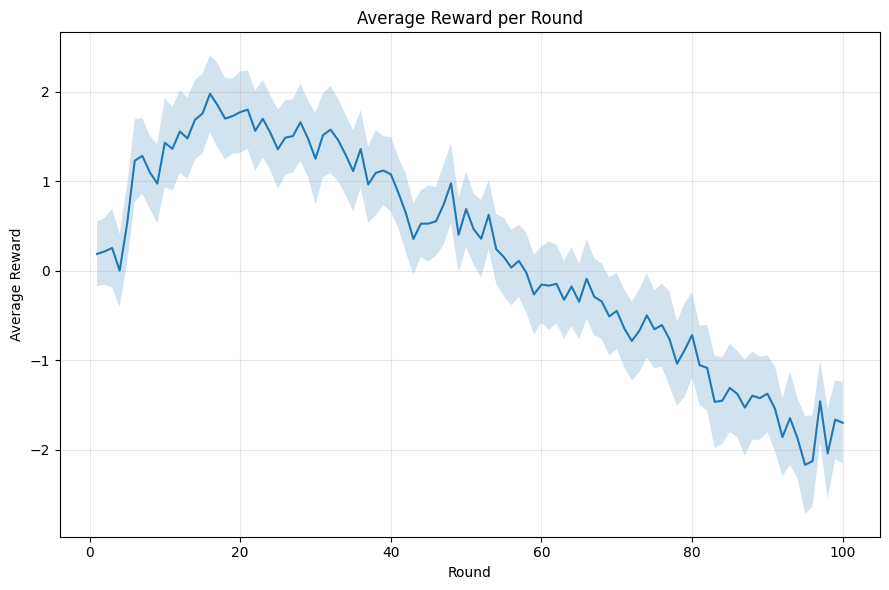

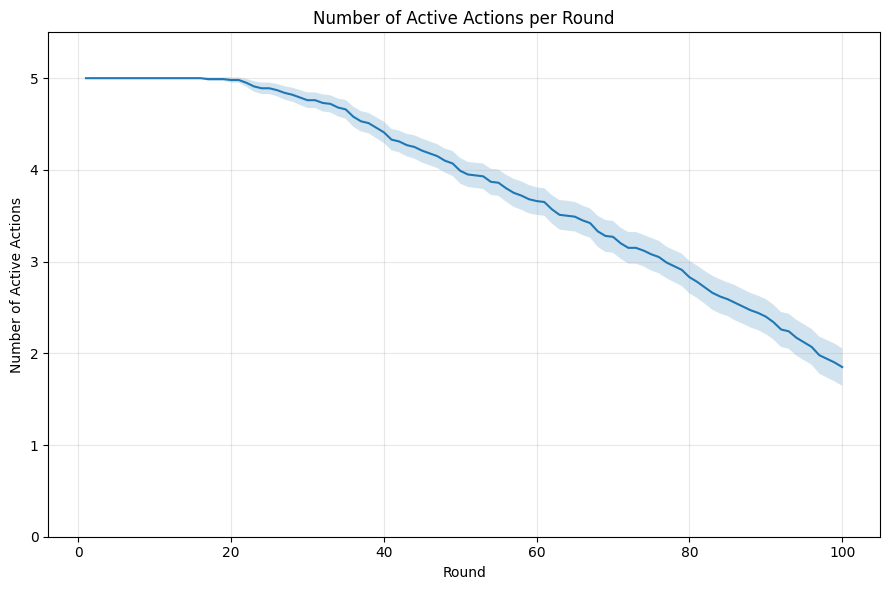

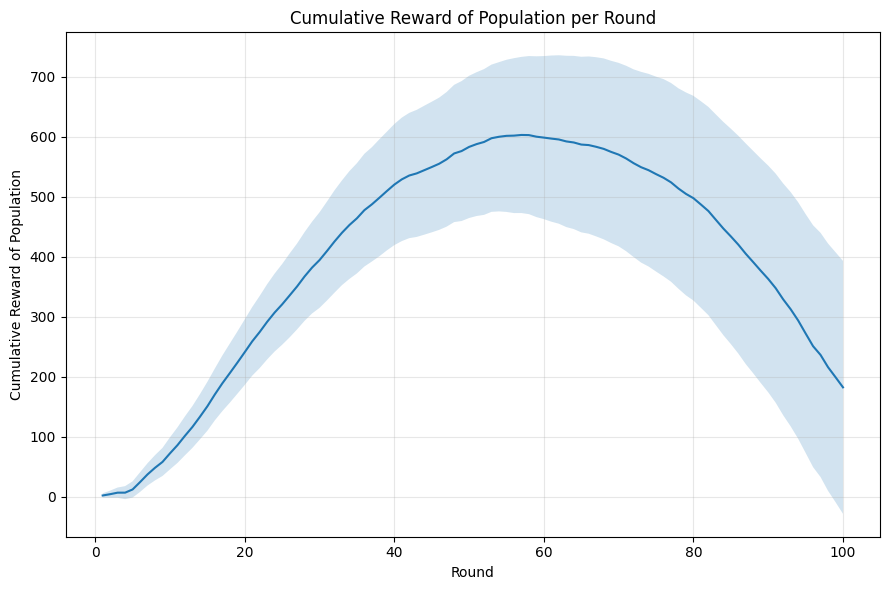

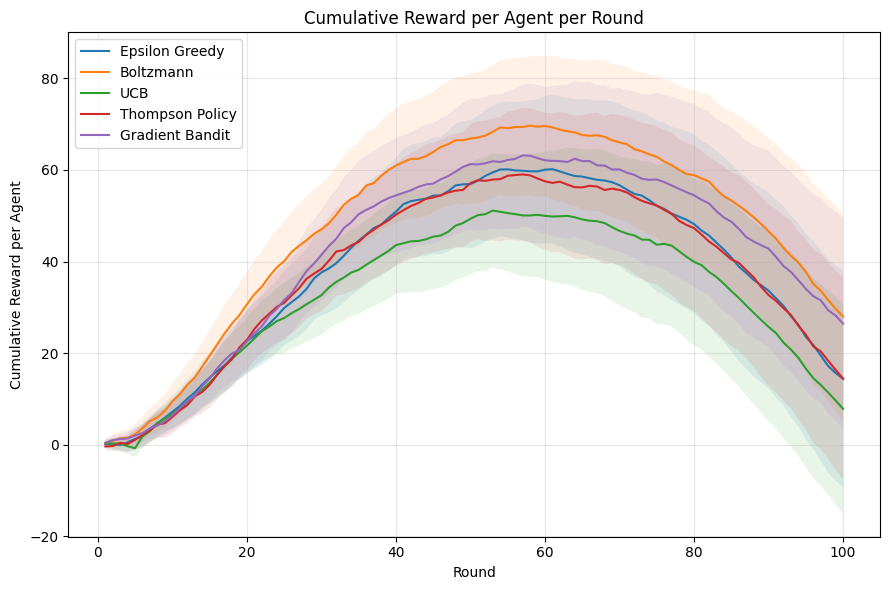

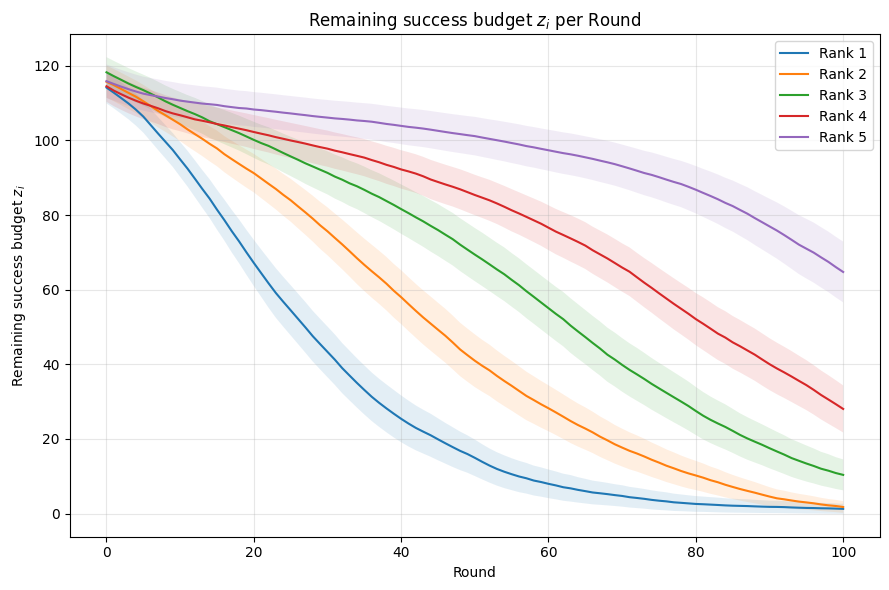

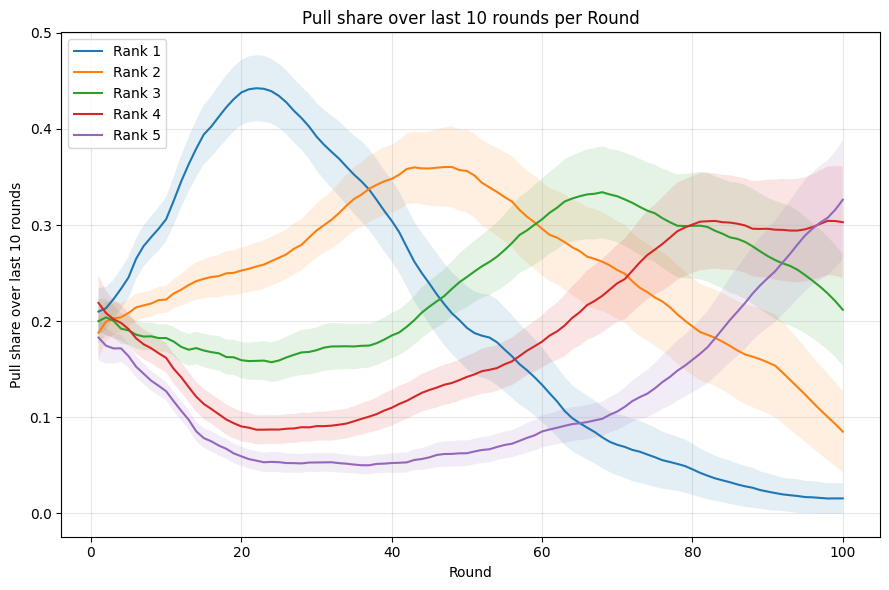

In [15]:
policies = []
for _ in range(2):
    policies.append(lambda: EpsilonGreedy(epsilon=eps, num_actions=NUM_ACTIONS))
    policies.append(lambda: Boltzmann(temperature=tau, num_actions=NUM_ACTIONS))
    policies.append(lambda: UCB(c=MAX_REWARD_ABS_VAL, num_actions=NUM_ACTIONS))
    policies.append(lambda: Thompson(num_actions=NUM_ACTIONS))
    policies.append(lambda: GradientBandit(alpha=alpha, num_actions=NUM_ACTIONS))

hetero_res = run_and_report(policies)

The average reward rises early as agents learn and exploit high-value actions, then declines steadily and eventually becomes negative. This is driven by the shared capacity constraint: the most rewarding actions are consumed first, so later choices are increasingly forced onto worse or negative-reward actions. The widening confidence intervals later in the run reflect growing variation across independent runs. The number of active actions follows a similar pattern, remaining stable at first and then declining almost monotonically as capacities are exhausted.

Cumulative population reward initially increases but peaks before the end of the experiment and then falls. This shows that early positive gains are partly offset by later forced choices with negative rewards. At the individual level, Boltzmann performs best in the selected setting, followed by Gradient Bandit, while ε-greedy and Thompson Sampling are intermediate and close to each other. UCB is the weakest curve over most of the run.

The remaining-budget plot shows that the highest-ranked action is exhausted much faster than the others, and the second-ranked action is also nearly exhausted by the end. Lower-ranked actions retain more budget, meaning agents concentrate first on the most valuable resources and only later move to inferior ones. The pull-share plot confirms this sequential substitution: the top action dominates early and then collapses, while the second, third, and later actions gain share at different later stages. Thus the important effect is not limited to the first action; rather, demand shifts progressively down the ranking as shared capacity is depleted.

* How does the population's reward change over time, and why?

The average reward increases until approximately round 15, after which it starts decreasing and becomes negative around round 60. Consequently, the cumulative social reward also starts decreasing from around round 60.

This is mainly due to limited resource capacities. As valuable actions with high expected rewards become depleted, agents are forced to select less valuable actions. Eventually, the remaining actions may have negative expected rewards, leading to negative average rewards for the population.

The condition for an action to have negative expected reward is $p_i r_{\max,i}+(1-p_i)r_{\min,i}<0$. It is not necessarily $p_i<0.5$.

* How does the deactivation of actions affect the algorithms' behavior?

The number of active actions gradually decreases. In our simulations, the first action becomes inactive between approximately rounds 20 and 55, depending on the run.

As available actions become fewer, agents are forced to select less valuable alternatives, which can reduce their rewards. Therefore, an effective algorithm should not only identify the best action but also learn the values of alternative actions so that it can adapt when the best actions become unavailable.

* Does an algorithm's successful individual performance necessarily have a positive impact on the population's total reward?

Not necessarily. An algorithm may repeatedly select the most rewarding action and achieve high individual rewards. However, doing so consumes that action's limited capacity more quickly, making it unavailable to other agents thus they would need to explore more to find the best action among the remaining actions.

Consequently, high individual performance does not necessarily lead to higher social welfare, since the actions of one agent can affect the rewards available to the rest of the population.

* Why might standard Bandit algorithms need to be modified for this environment?

Standard Bandit algorithms do not explicitly account for competition among agents over shared, limited resources. In this environment, actions can become inactive as their capacities are depleted, changing the set of available choices over time.

Moreover, algorithms that account for the presence and decisions of other agents could potentially improve the population's total reward through better resource utilization and coordination.

* How do algorithm hyperparameters affect performance?

Hyperparameters control the exploration–exploitation trade-off, although their effects depend on the algorithm. For example, increasing $\epsilon$ increases random exploration in Epsilon-Greedy, while increasing the temperature in Boltzmann makes action selection more exploratory. In UCB, increasing $c$ strengthens the exploration bonus, and in Gradient Bandit, increasing $\alpha$ makes preference updates larger.

More exploration may initially reduce individual rewards but help agents learn about alternative actions that become useful when the best actions are depleted. Conversely, greater exploitation may provide higher immediate rewards but can cause agents to compete more heavily for the same valuable resources.

# B) Social Regret

1. Can standard single-agent Bandit regret be used in this environment without modification? Why?

Not as a measure of social performance. Standard regret compares an agent's cumulative reward with the reward it could have obtained by always selecting the best action. However, in this environment, agents share limited resources. Maximizing each agent's individual reward does not necessarily maximize the population's total reward. Therefore, standard regret does not fully capture the social objective.

2. How do shared capacity constraints and the influence of agents on one another affect the definition of the optimal action or policy?

The optimal choice is no longer necessarily the action with the highest individual expected reward. It should account for the remaining capacity of actions and the effect of each agent's selection on the opportunities available to other agents. Thus, the relevant optimum is a joint policy that maximizes the population's cumulative reward.

3. Does maximizing individual reward necessarily maximize social reward?

No. If all agents repeatedly select the same highest-reward action, they may deplete its capacity quickly. They must then explore other actions, potentially receiving lower or negative rewards. A coordinated allocation of agents across different actions could use resources more efficiently and increase total cumulative reward.

4. Define Social Regret and explain what additional information an optimal policy requires.

In the standard single-agent Bandit setting, regret is defined as:

$$
R(T)=T\mu^*-\sum_{i=1}^{N}\mathbb{E}[T_i]\mu_i
$$

where $\mu^*$ is the highest expected action reward, $\mu_i$ is the expected reward of action $i$, and $T_i$ is the number of times action $i$ is selected.

For a population of $A$ agents, we define Social Regret as the difference between the expected reward of an optimal joint policy and the expected total reward obtained by the agents:

$$
SR(T)=V^*_{\mathrm{social}}(T)-
\mathbb{E}\left[\sum_{t=1}^{T}\sum_{j=1}^{A}r_{j,t}\right]
$$

Here, $V^*_{\mathrm{social}}(T)$ is the maximum expected cumulative reward achievable by the oracle.

In this environment, the oracle can rank actions according to their expected rewards and allocate all agents to the highest-reward available action until its success budget is exhausted. It then moves to the next-highest-reward action. Therefore, it needs the expected reward and remaining success budget of each action, in addition to the number of agents.

# C) Homogeneous Popoulation

I ran the following algorithms in homogenous population with two different configurations, the default and the double hyperparameter value. Both configs were run 100 times and the seeds used were the same for fair comparison.

## Eps-Greedy

Eps = 0.09999999999999999


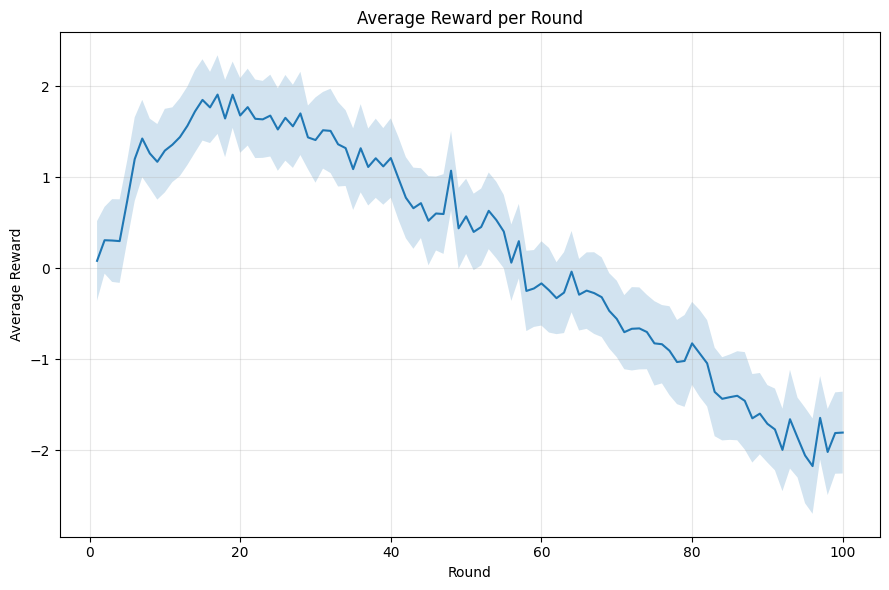

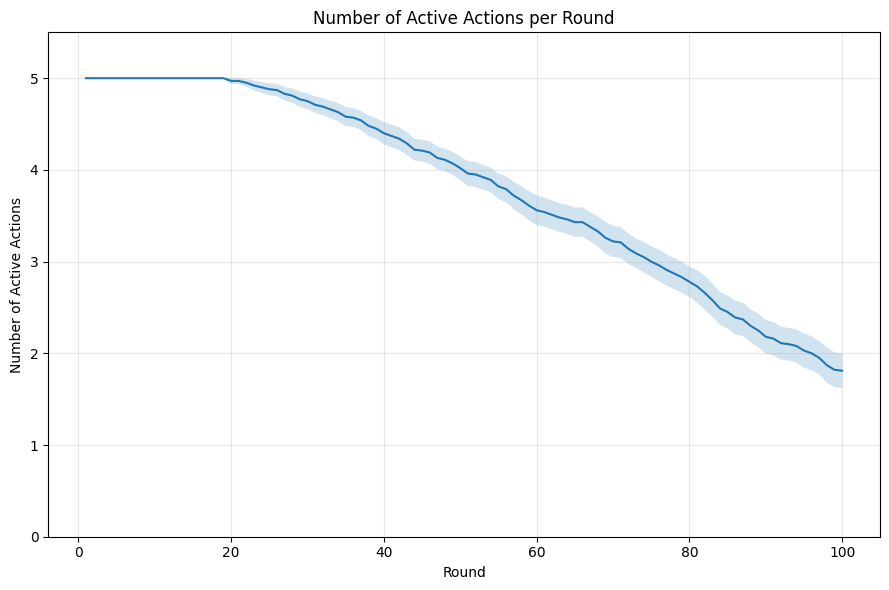

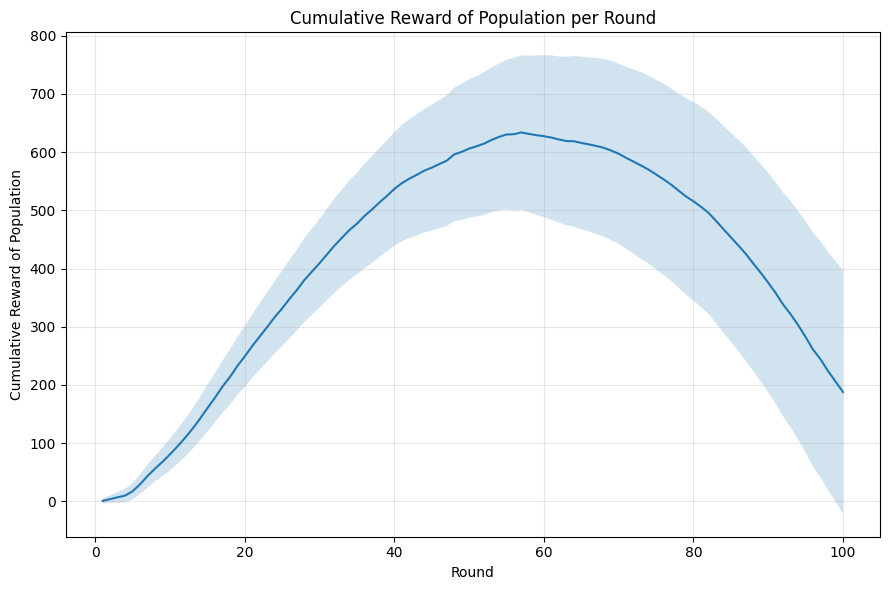

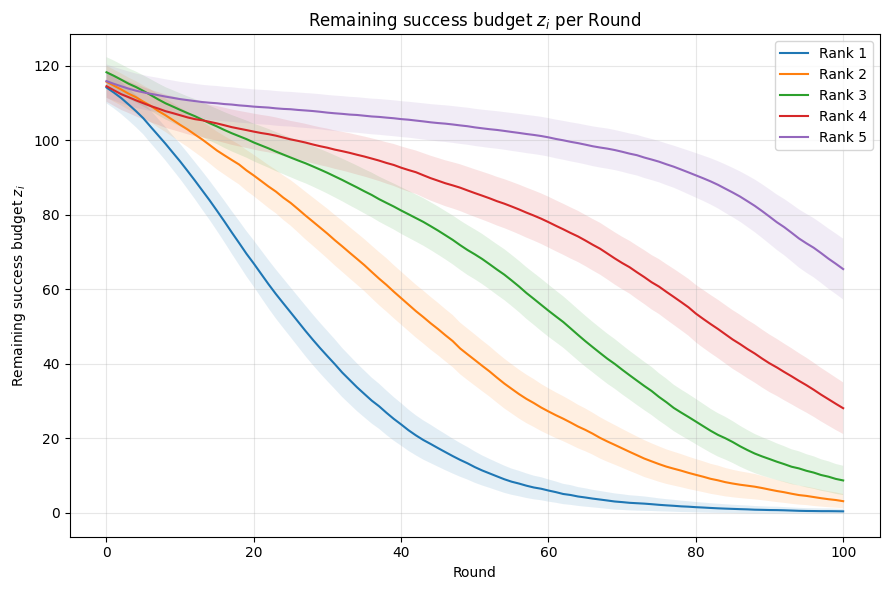

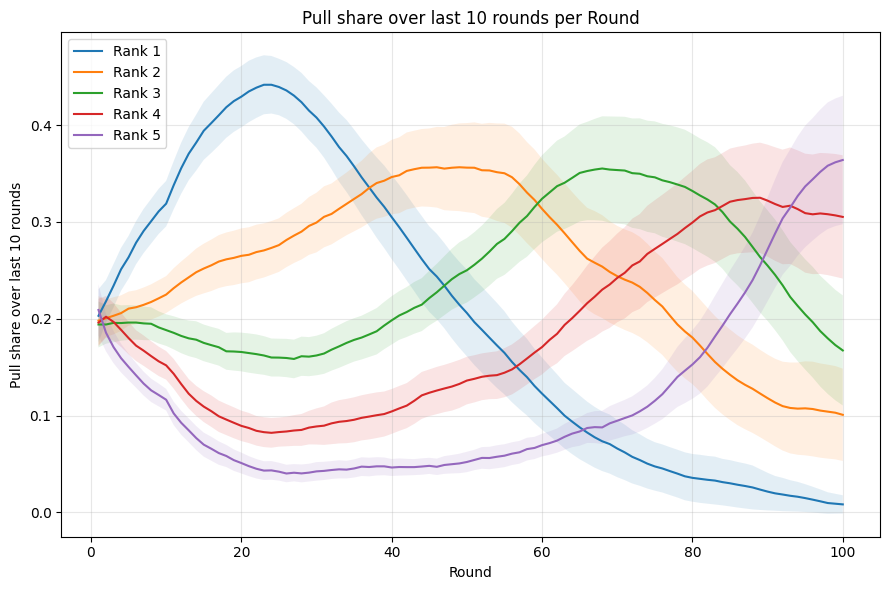

Eps = 0.19999999999999998


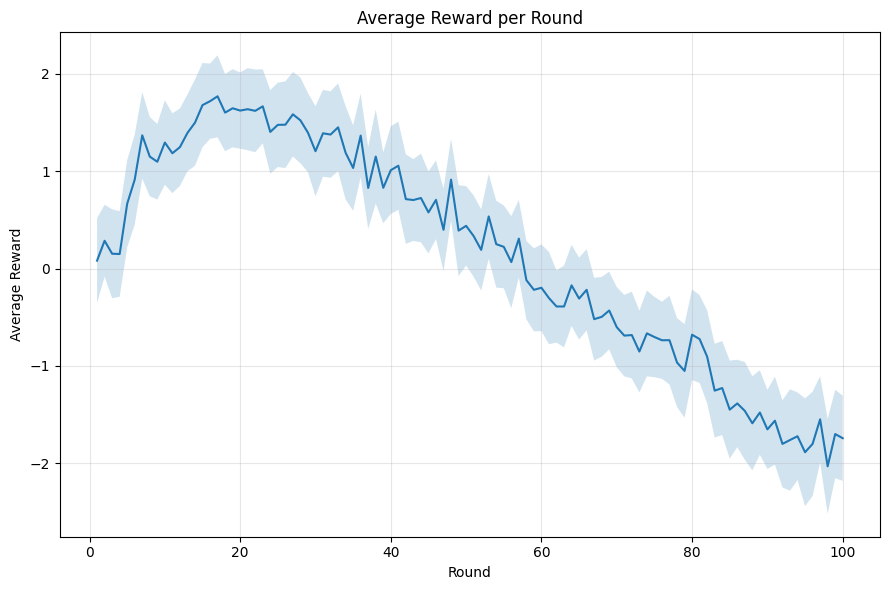

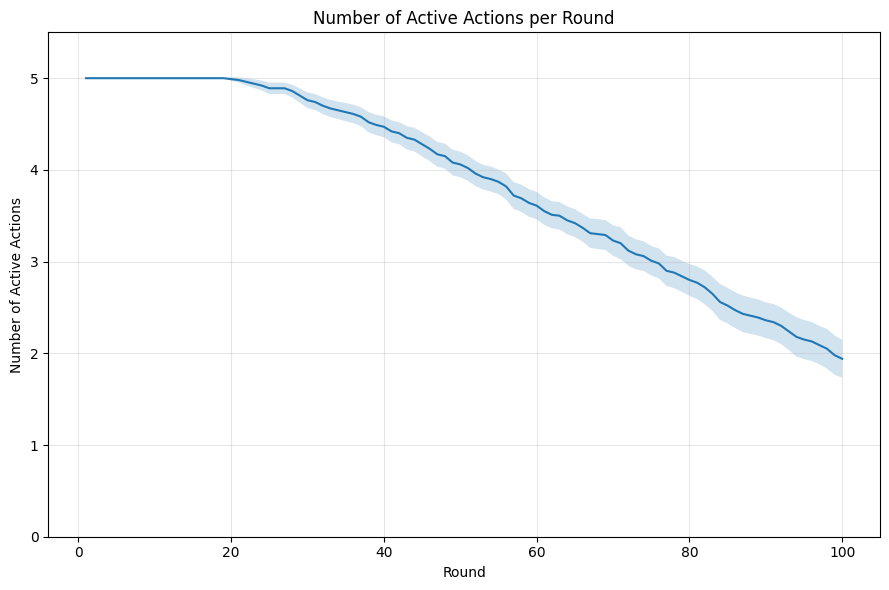

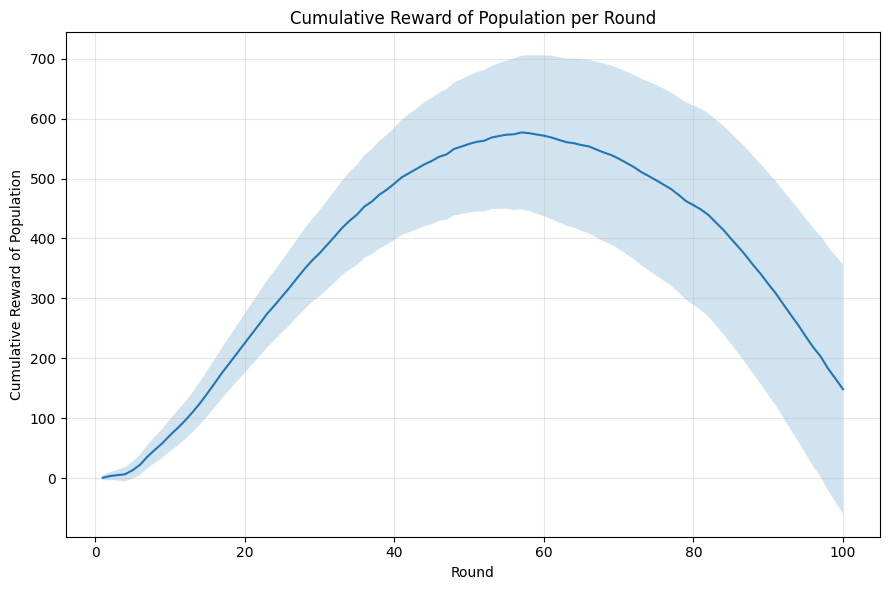

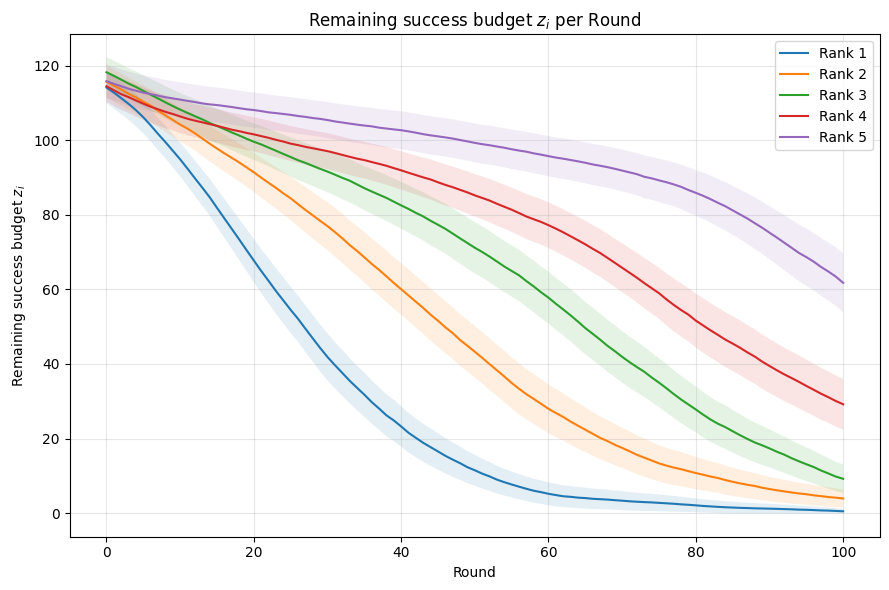

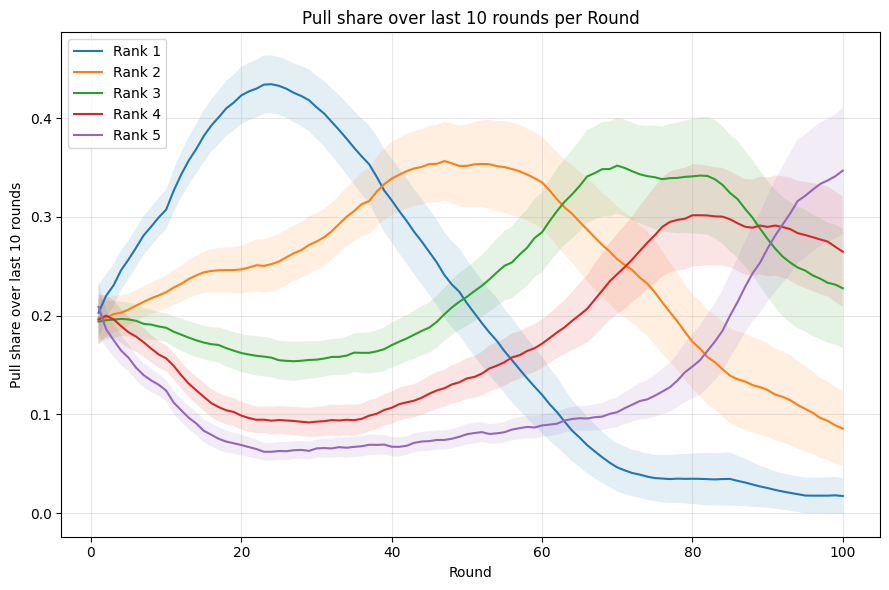

In [16]:
policies = []
for _ in range(10):
    policies.append(lambda: EpsilonGreedy(epsilon=eps, num_actions=NUM_ACTIONS, name=f"Epsilon Greedy eps={eps:.3f}"))
print("Eps =", eps)
eg_res1 = run_and_report(policies)

eps2 = 2*eps
policies = []
for _ in range(10):
    policies.append(lambda: EpsilonGreedy(epsilon=eps2, num_actions=NUM_ACTIONS, name=f"Epsilon Greedy eps={eps2:.3f}"))
print("="*100)
print("Eps =", eps2)
eg_res2 = run_and_report(policies)

## UCB

C = 10.0


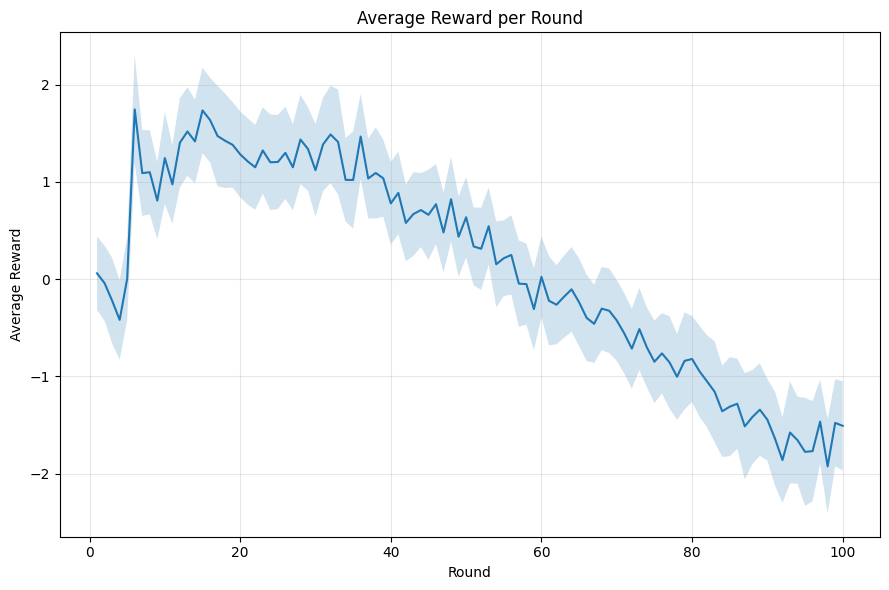

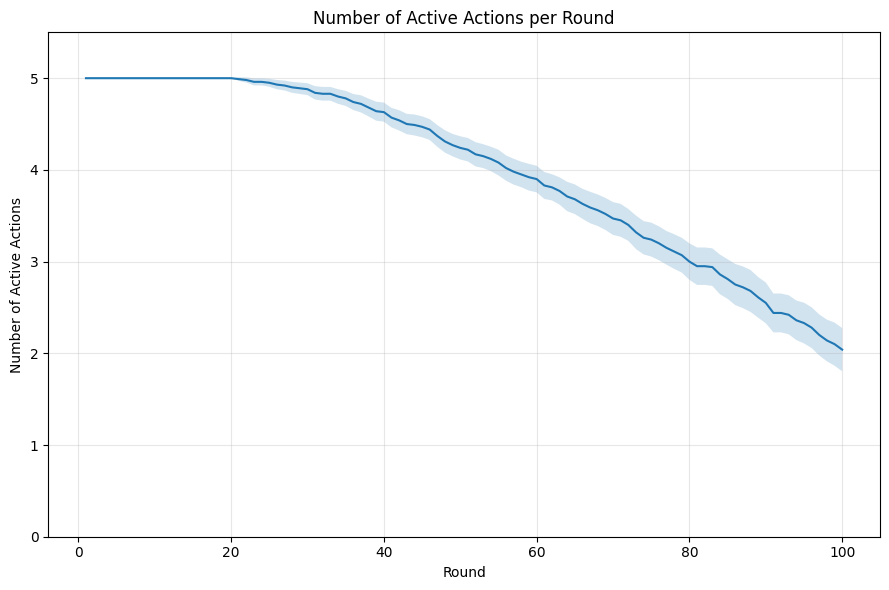

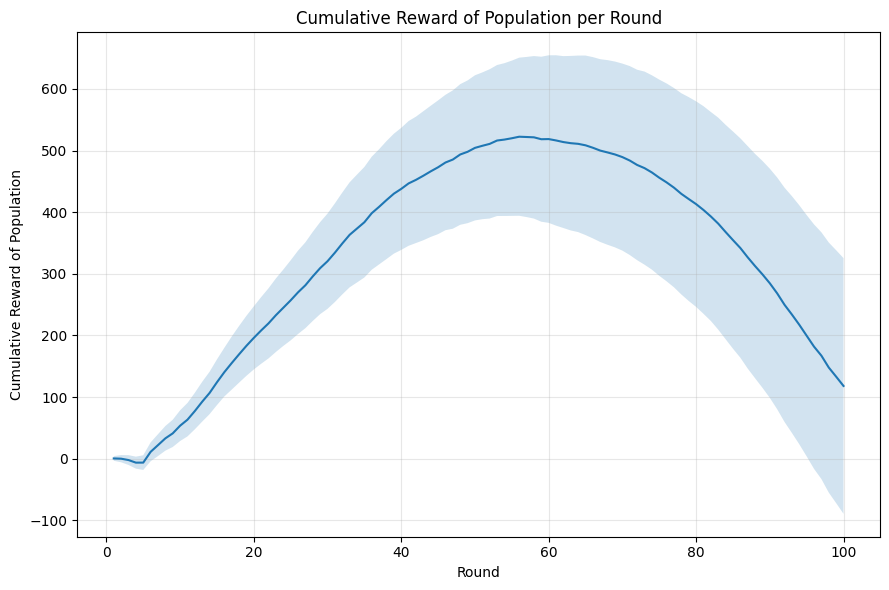

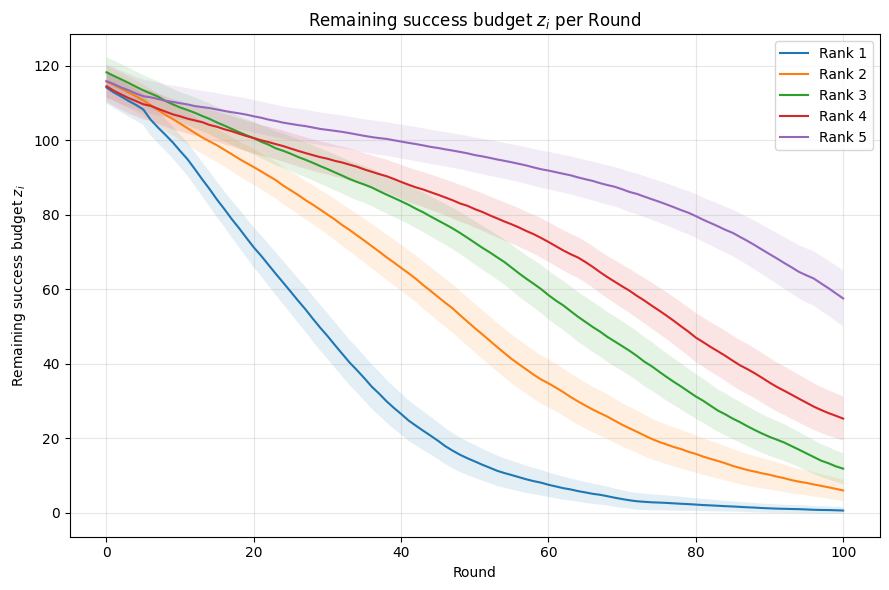

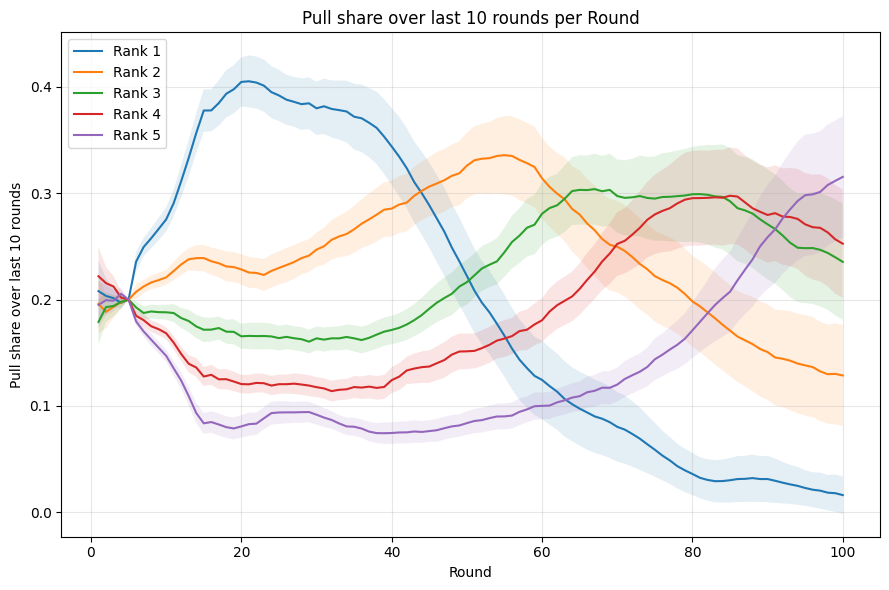

C = 20.0


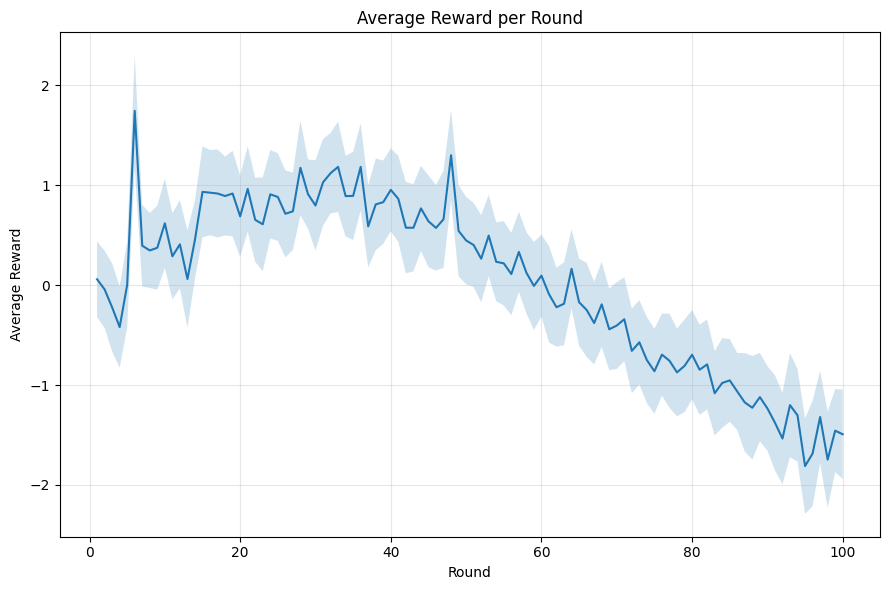

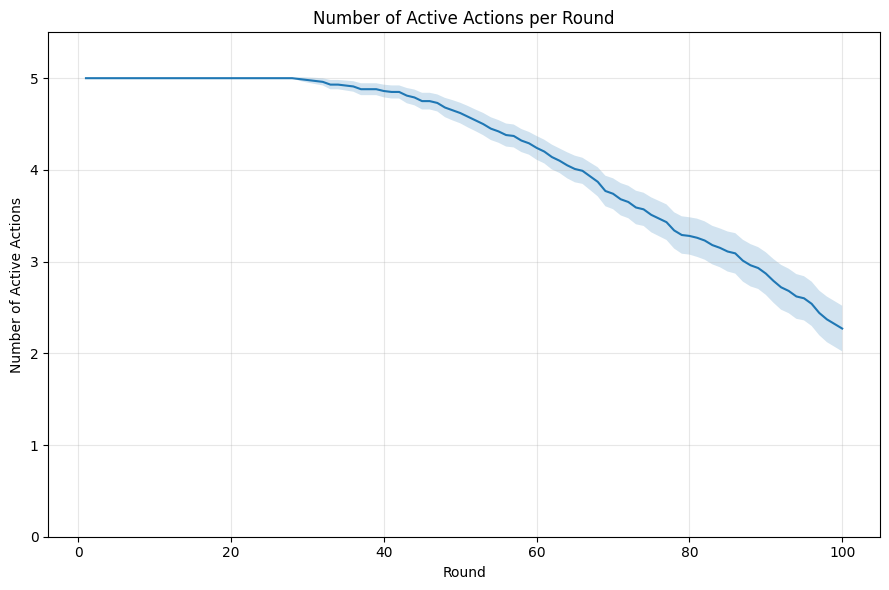

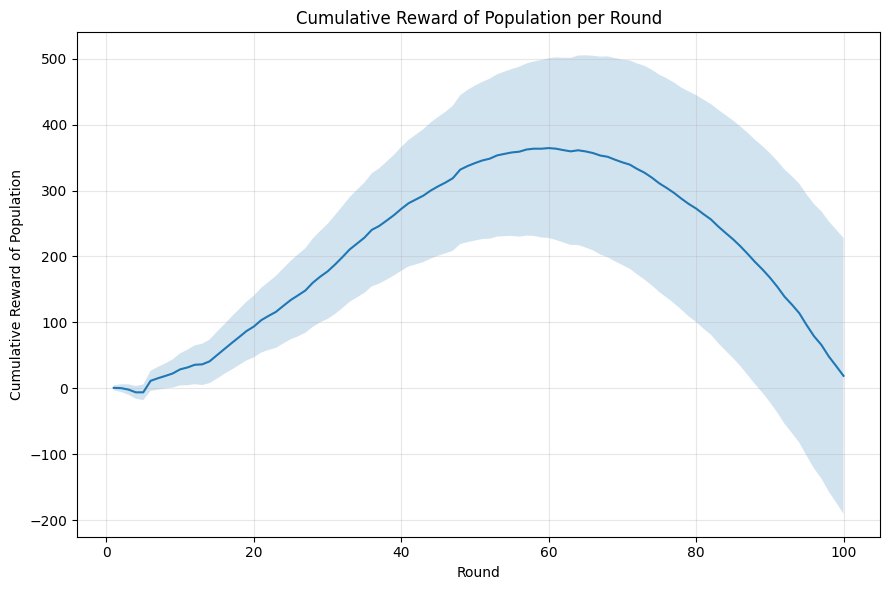

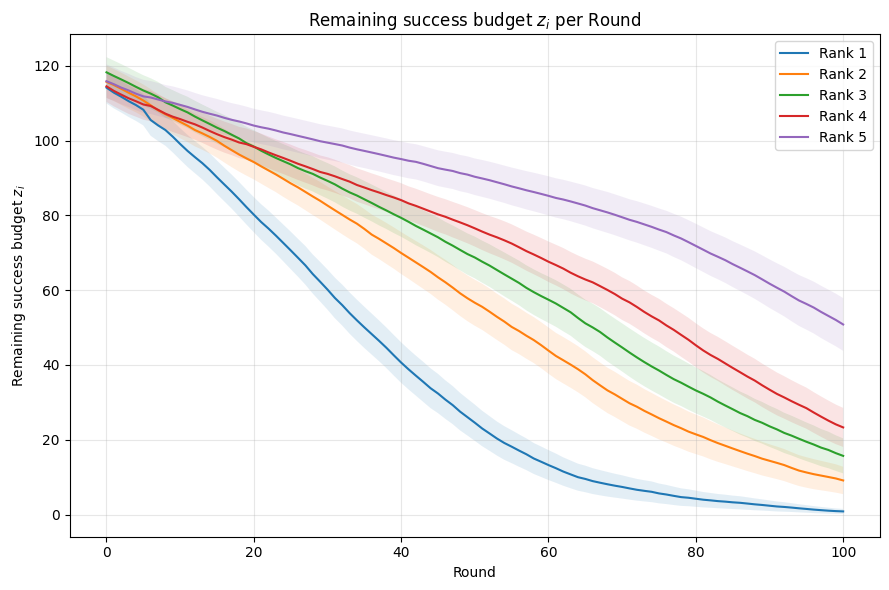

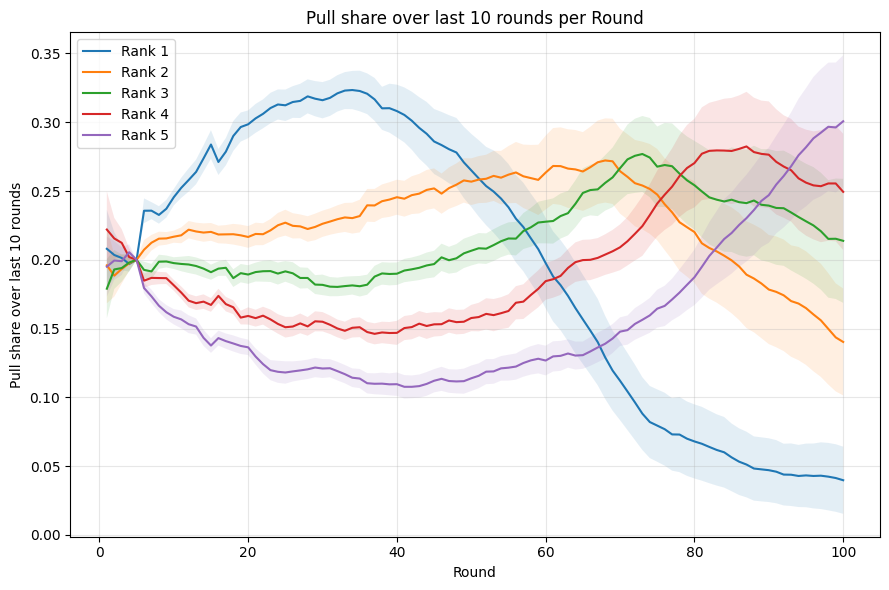

In [17]:
policies = []
for _ in range(10):
    policies.append(lambda: UCB(c=MAX_REWARD_ABS_VAL, num_actions=NUM_ACTIONS, name=f"UCB C={MAX_REWARD_ABS_VAL:.3f}"))
print("C =", MAX_REWARD_ABS_VAL)
ucb_res1 = run_and_report(policies)

policies = []
c2 = 2*MAX_REWARD_ABS_VAL
for _ in range(10):
    policies.append(lambda: UCB(c=c2, num_actions=NUM_ACTIONS, name=f"UCB C={c2:.3f}"))
print("="*100)
print("C =", c2)
ucb_res2 = run_and_report(policies)

## Gradient Bandit

Alpha = 0.19


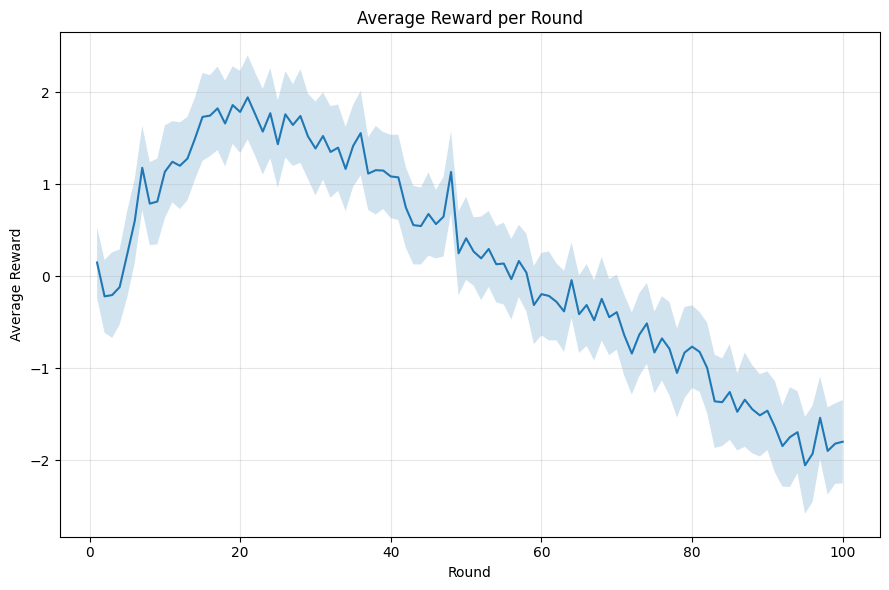

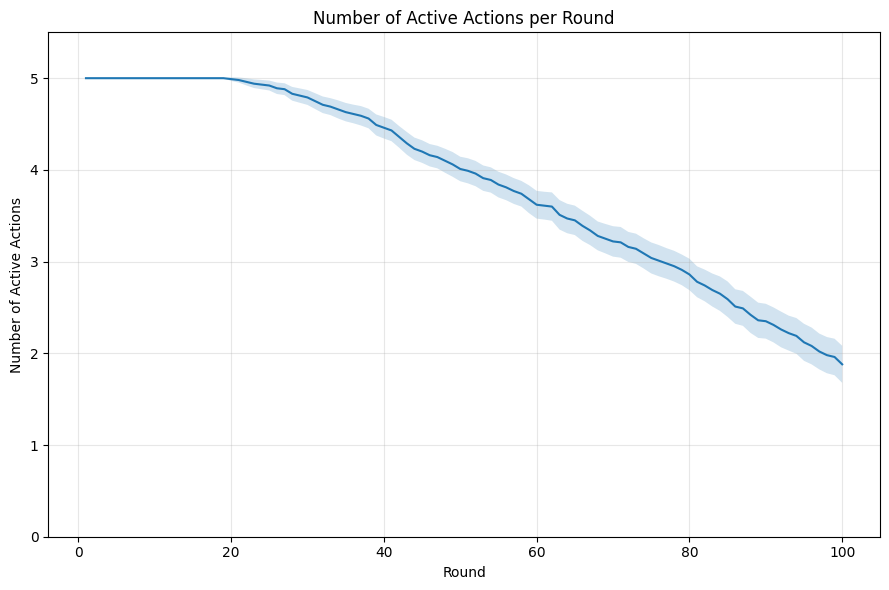

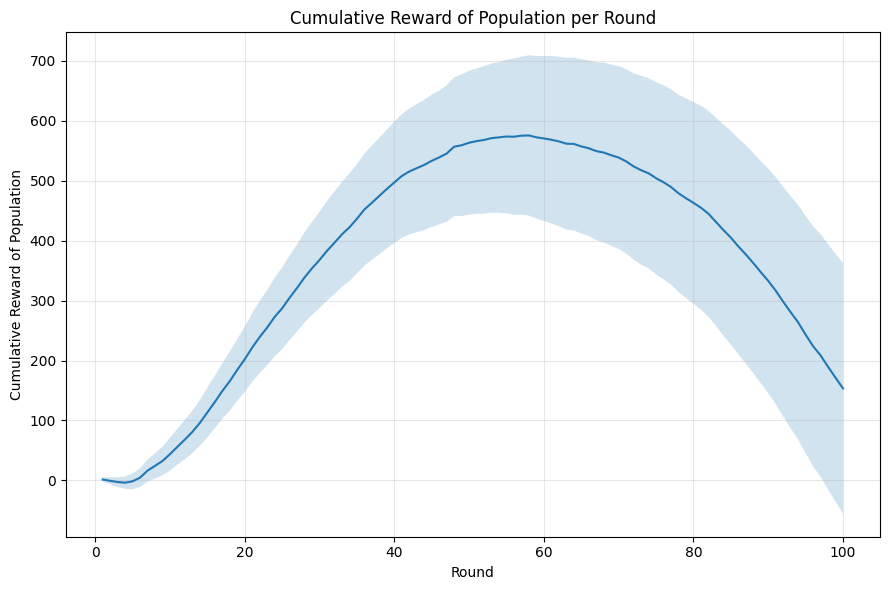

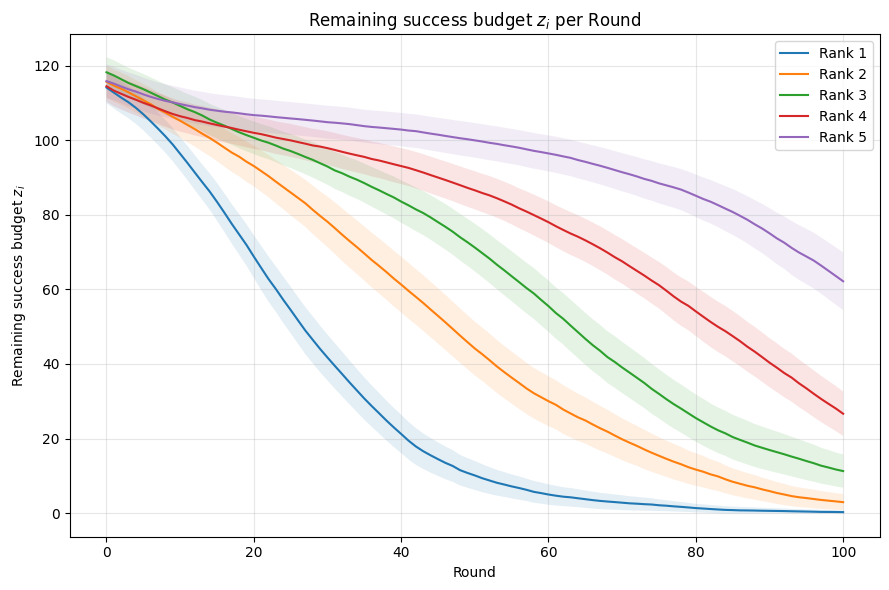

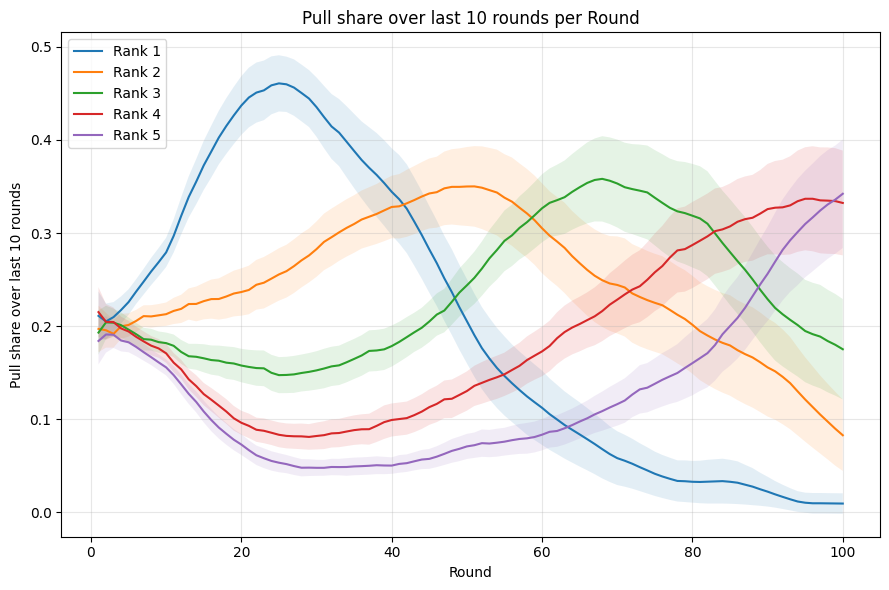

Alpha = 0.38


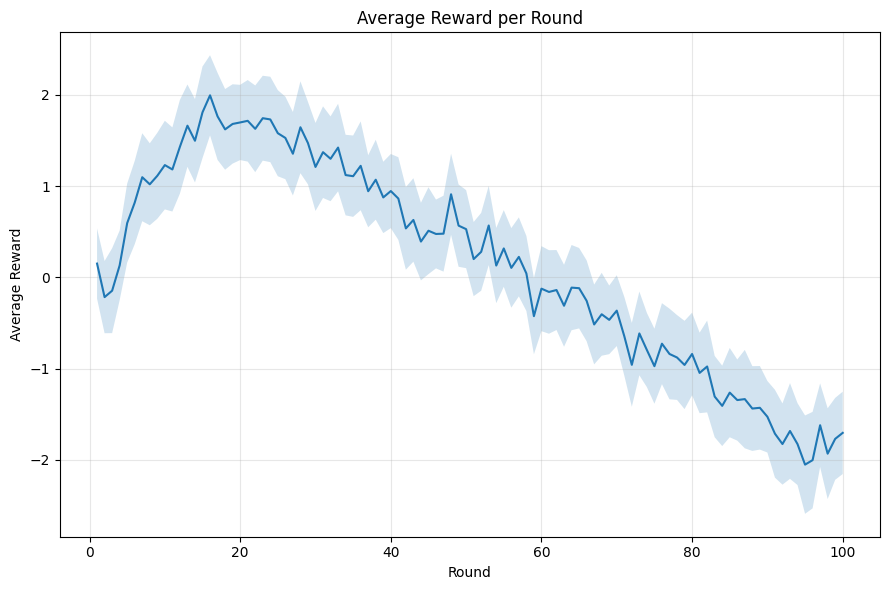

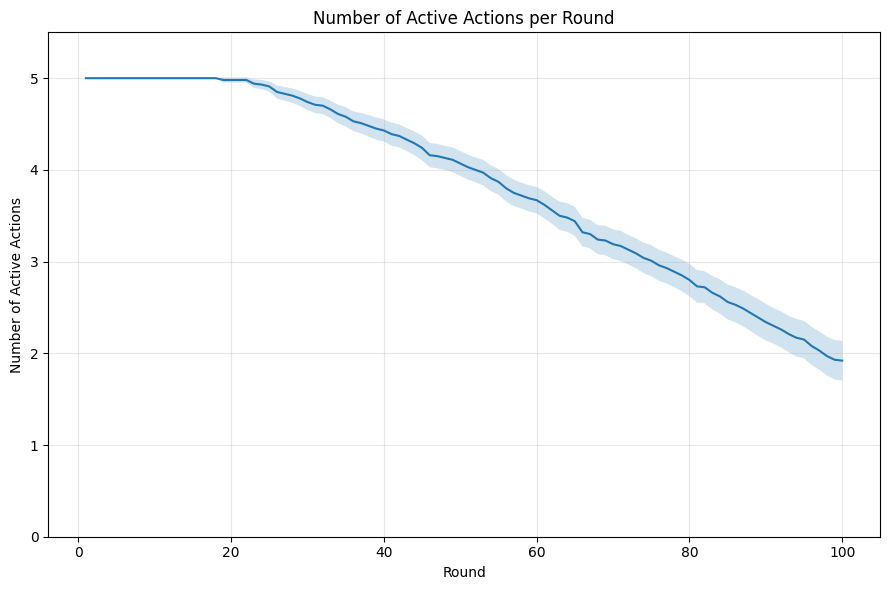

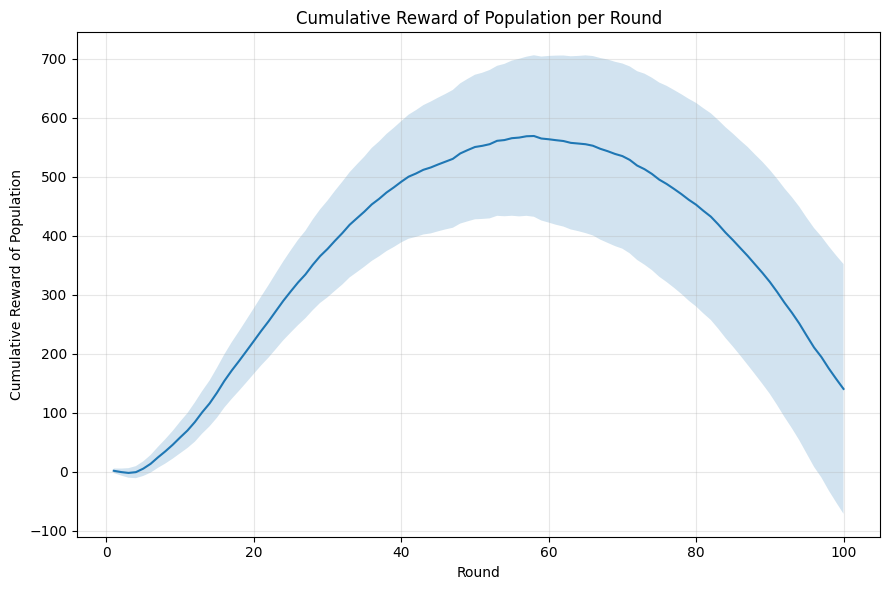

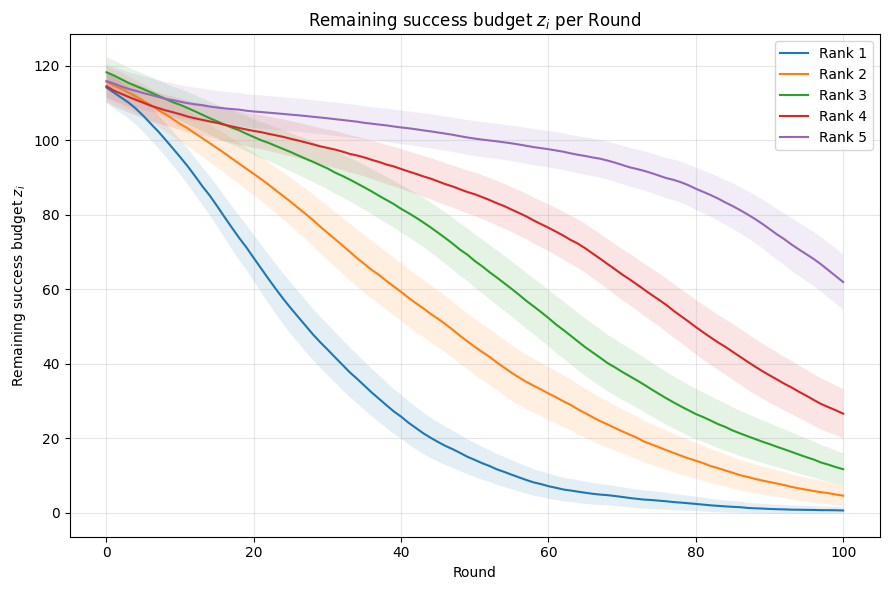

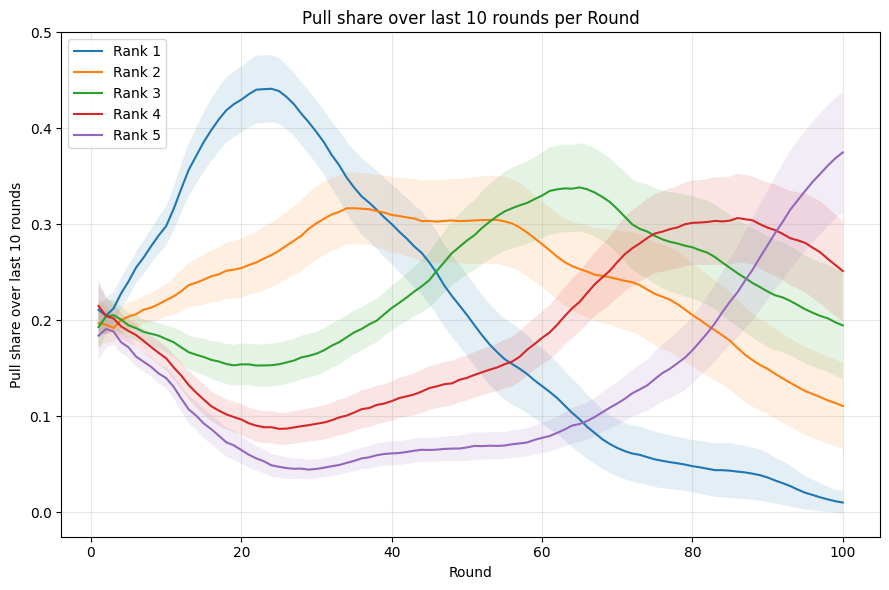

In [18]:
policies = []
for _ in range(10):
    policies.append(lambda: GradientBandit(alpha=alpha, num_actions=NUM_ACTIONS, name=f"Gradient Bandit alpha={alpha:.3f}"))
print("Alpha =", alpha)
gb_res1 = run_and_report(policies)

policies = []
alpha2 = 2*alpha
for _ in range(10):
    policies.append(lambda: GradientBandit(alpha=alpha2, num_actions=NUM_ACTIONS, name=f"Gradient Bandit alpha={alpha2:.3f}"))
print("="*100)
print("Alpha =", alpha2)
gb_res2 = run_and_report(policies)

## Analysis

* Does the algorithm that receives rewards faster at the beginning of the experiment necessarily perform better at the end?

No. By comparing the average cumulative reward per algorithm, we can see that an algorithm may perform better during the initial rounds, while another algorithm may eventually overtake it and maintain its advantage until the end. This may be related to the exploration-exploitation trade-off: more exploration can reduce early rewards but may help an algorithm discover better actions for later rounds.

* How does the speed of resource consumption affect the final reward?

In our results, algorithms with higher early reward peaks also achieve higher final cumulative rewards. This suggests that selecting higher-reward actions more frequently leads to better overall performance in these experiments. Although successful selections consume the capacity of those actions, the immediate rewards they provide appear to outweigh the cost of their depletion in our results.

Since every agent makes one selection per turn, the total number of selection opportunities is the same across algorithms. The main difference is therefore which actions they select and how the shared capacities are consumed.

* Is the difference between algorithms statistically siginficant?

Let's use paired t-tests to compare the final cumulative rewards of the algorithms:

In [19]:
configs = {
    "Epsilon-Greedy":  list(eg_res1["raw_cum_algo"].keys())[0],
    "UCB":             list(ucb_res1["raw_cum_algo"].keys())[0],
    "Gradient Bandit": list(gb_res1["raw_cum_algo"].keys())[0],
}

results = {
    "Epsilon-Greedy":  eg_res1,
    "UCB":             ucb_res1,
    "Gradient Bandit": gb_res1,
}

scores = {
    name: results[name]["raw_cum_algo"][configs[name]][:, -1]
    for name in configs
}

comparisons = []

for name1, name2 in combinations(scores.keys(), 2):
    x = scores[name1]
    y = scores[name2]

    differences = x - y
    t_stat, p_value = stats.ttest_rel(x, y)

    comparisons.append({
        "Algorithm 1": name1,
        "Algorithm 2": name2,
        "Mean difference": differences.mean(),
        "t-statistic": t_stat,
        "p-value": p_value,
        "Cohen's dz": differences.mean() / differences.std(ddof=1),
    })

first_tests = pd.DataFrame(comparisons)

first_tests["p-adjusted"] = multipletests(
    first_tests["p-value"], method="holm"
)[1]

first_tests["Significant"] = first_tests["p-adjusted"] < 0.05

display(first_tests.sort_values("p-adjusted"))

,Algorithm 1,Algorithm 2,Mean difference,t-statistic,p-value,Cohen's dz,p-adjusted,Significant
0,Epsilon-Greedy,UCB,6.972831,5.177097,0.000001,0.517710,0.000004,True
2,UCB,Gradient Bandit,-3.531799,-3.100665,0.002515,-0.310066,0.005030,True
1,Epsilon-Greedy,Gradient Bandit,3.441031,2.305698,0.023214,0.230570,0.023214,True


All three pairwise comparisons are statistically significant at the 5% level after correction. The effect sizes, measured by Cohen's $d_z$, are approximately 0.52 for Epsilon-Greedy versus UCB, 0.31 for UCB versus Gradient Bandit, and 0.23 for Epsilon-Greedy versus Gradient Bandit. These indicate differences of varying magnitudes, with the largest standardized difference between Epsilon-Greedy and UCB.

* How much do the results depend on the algorithm configs?

To investigate the dependence of results on algorithm configurations, we compared the final cumulative rewards using paired t-tests:

In [20]:
sensitivity = [
    ("Epsilon-Greedy", eg_res1, eg_res2),
    ("UCB", ucb_res1, ucb_res2),
    ("Gradient Bandit", gb_res1, gb_res2),
]

rows = []
for name, original, modified in sensitivity:
    k1 = list(original["raw_cum_algo"])[0]
    k2 = list(modified["raw_cum_algo"])[0]
    x = original["raw_cum_algo"][k1][:, -1]
    y = modified["raw_cum_algo"][k2][:, -1]
    t, p = stats.ttest_rel(y, x)
    rows.append({
        "Algorithm": name,
        "Original mean": x.mean(),
        "Modified mean": y.mean(),
        "Difference": (y - x).mean(),
        "p-value": p,
    })

sensitivity_tests = pd.DataFrame(rows)
sensitivity_tests["Adjusted p-value"] = multipletests(
    sensitivity_tests["p-value"], method="holm"
)[1]
sensitivity_tests["Significant"] = sensitivity_tests["Adjusted p-value"] < 0.05

display(sensitivity_tests)

,Algorithm,Original mean,Modified mean,Difference,p-value,Adjusted p-value,Significant
0,Epsilon-Greedy,18.787340,14.861254,-3.926086,2.422598e-03,4.845195e-03,True
1,UCB,11.814509,1.881634,-9.932875,4.109862e-10,1.232958e-09,True
2,Gradient Bandit,15.346309,14.025110,-1.321199,3.651331e-01,3.651331e-01,False


Doubling $\epsilon$ reduces Epsilon-Greedy's mean final reward by approximately 3.93, while doubling $c$ reduces UCB's mean by approximately 9.93. Both differences are statistically significant. For Gradient Bandit, doubling $\alpha$ reduces the mean by approximately 1.32, but this difference is not statistically significant.

Therefore, among these particular parameter changes, UCB shows the largest decrease in performance, while Gradient Bandit appears less sensitive. This conclusion applies only to the tested parameter values and does not imply that Gradient Bandit is generally insensitive to its learning rate.

# Measure sensitivity

## K = 30

Increasing the number of agents increases competition for shared resources, causing action capacities to be depleted faster. Therefore, agents have less time to learn which actions are most rewarding before some of them become unavailable. I expect this to increase competition between algorithms and shorten the period during which high-reward actions remain available.

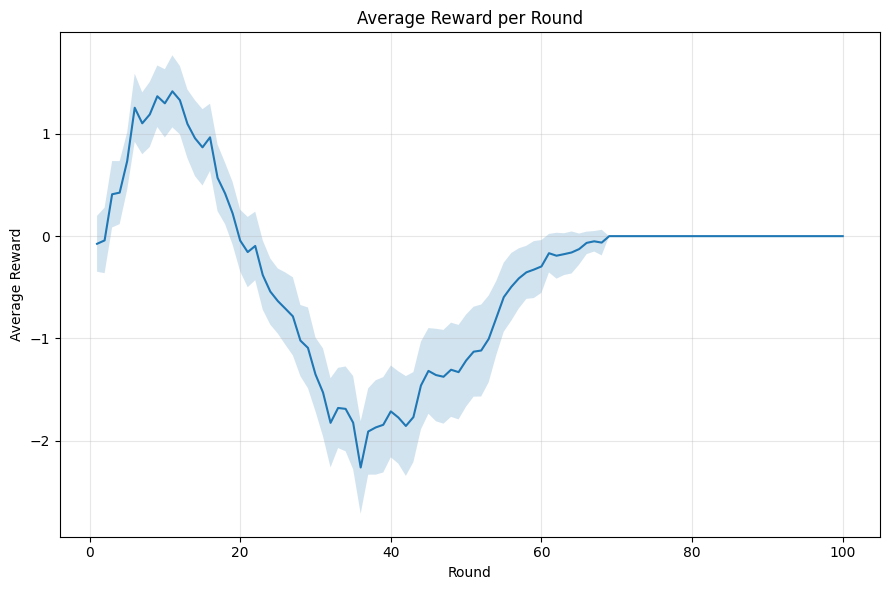

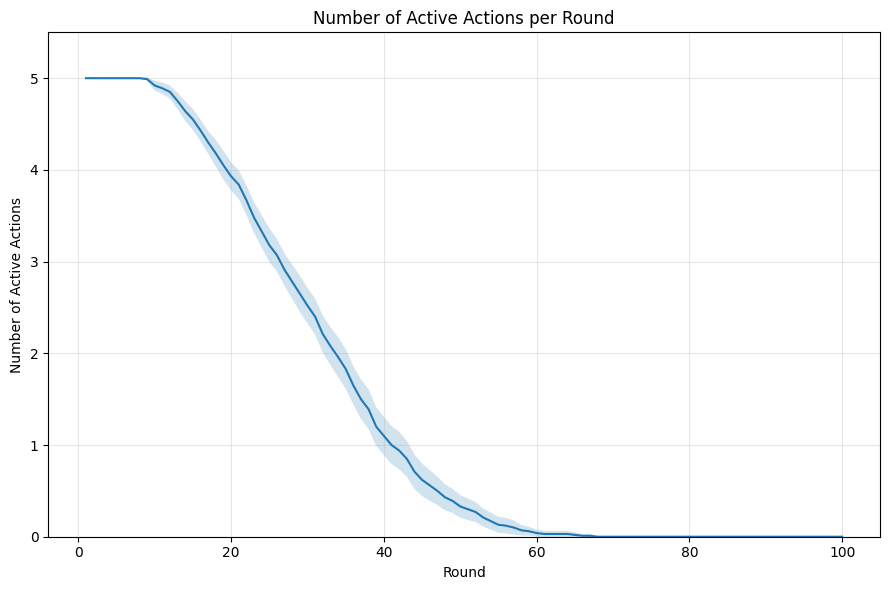

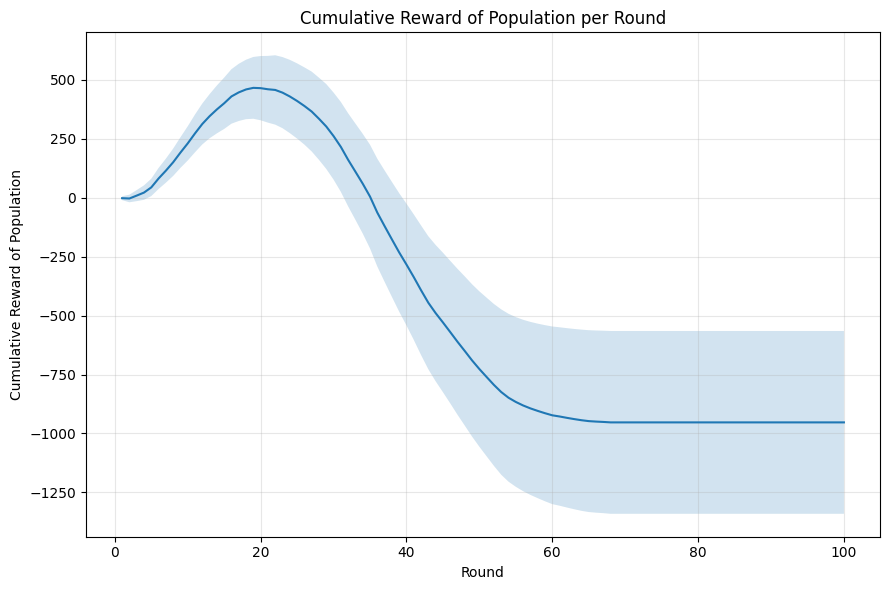

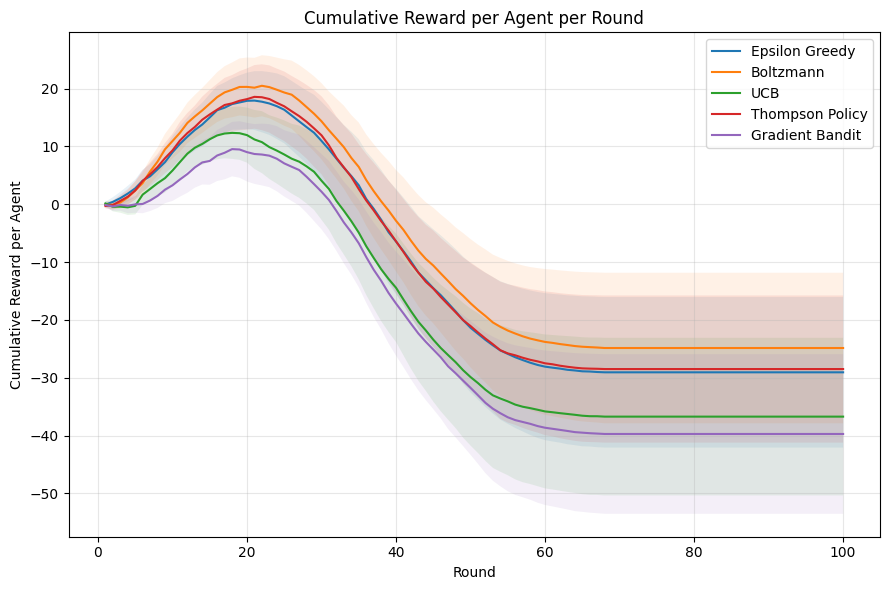

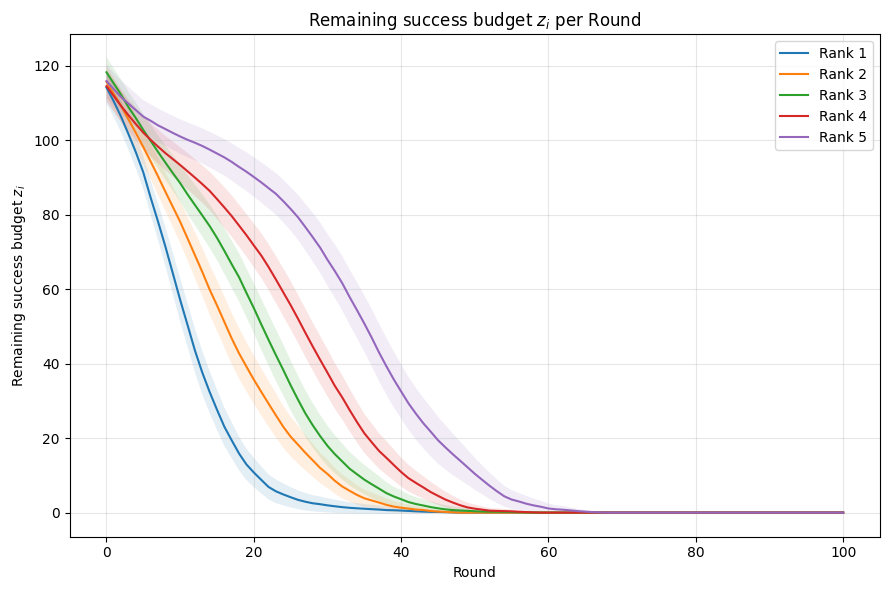

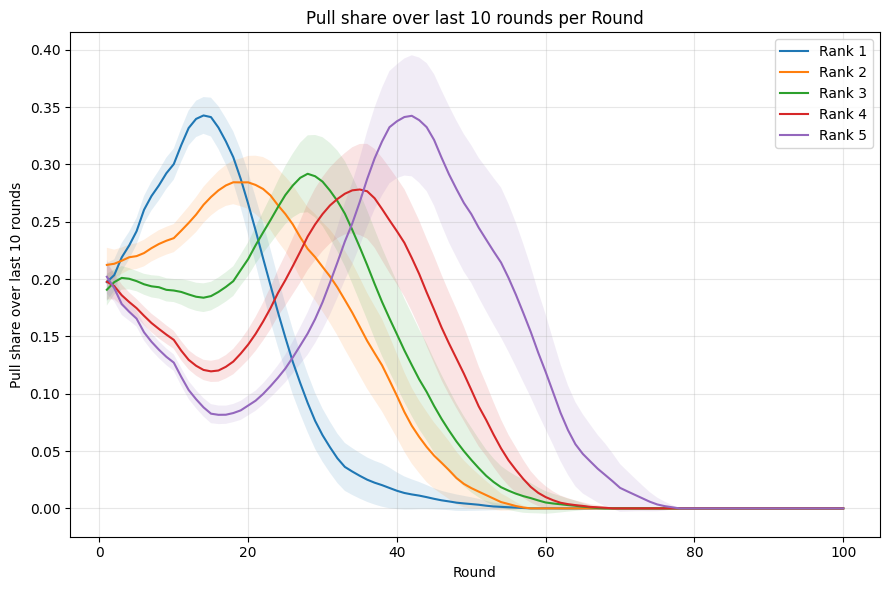

In [21]:
policies = []
for _ in range(6):
    policies.append(lambda: EpsilonGreedy(epsilon=eps, num_actions=NUM_ACTIONS))
    policies.append(lambda: Boltzmann(temperature=tau, num_actions=NUM_ACTIONS))
    policies.append(lambda: UCB(c=MAX_REWARD_ABS_VAL, num_actions=NUM_ACTIONS))
    policies.append(lambda: Thompson(num_actions=NUM_ACTIONS))
    policies.append(lambda: GradientBandit(alpha=alpha, num_actions=NUM_ACTIONS))

k_res = run_and_report(policies)

The average expected reward initially decreases but later increases. This can happen because the actions selected by agents change as resources become depleted, altering the average expected reward of the selected actions. The pull-share plot also shows a peak for the worst-ranked action around round 40. This is likely because most higher-ranked actions have become inactive, forcing agents to select the remaining, less desirable action.

## $z_i \sim U_{discrete}\{1,2,...,150\}$

Reducing the minimum possible value of $z_i$ increases the variation in initial action capacities and makes some actions deplete much earlier. I therefore expect greater variability across simulation runs and potentially wider confidence intervals. I also expect lower cumulative reward because agents may lose access to valuable actions sooner.

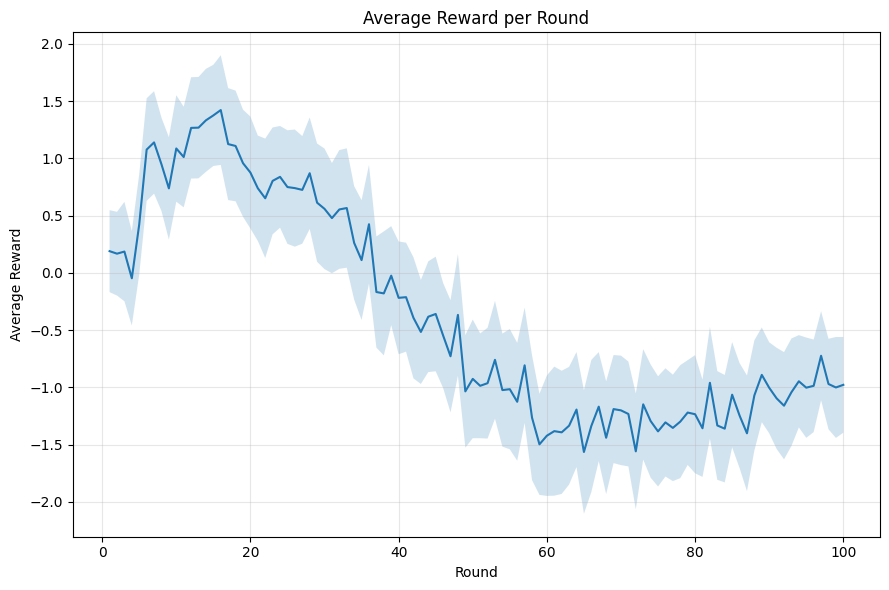

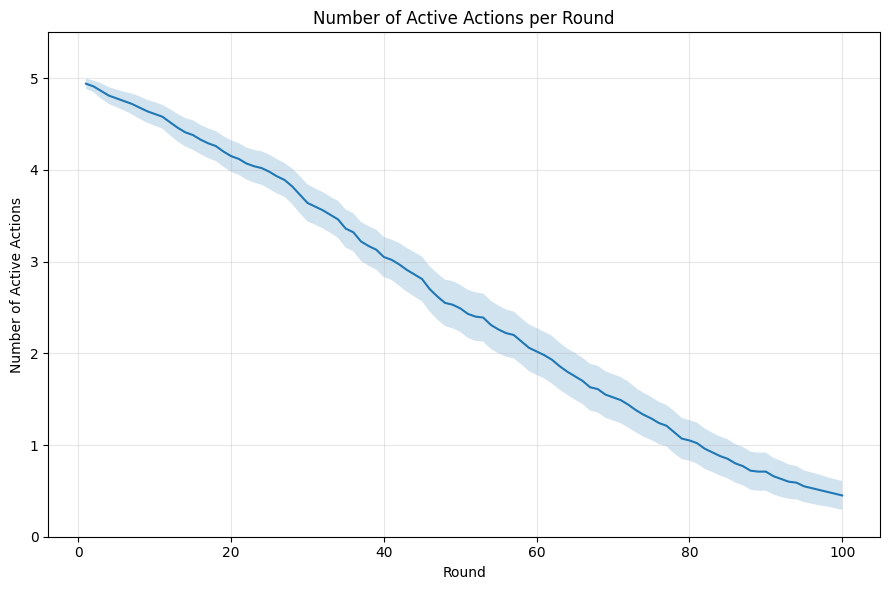

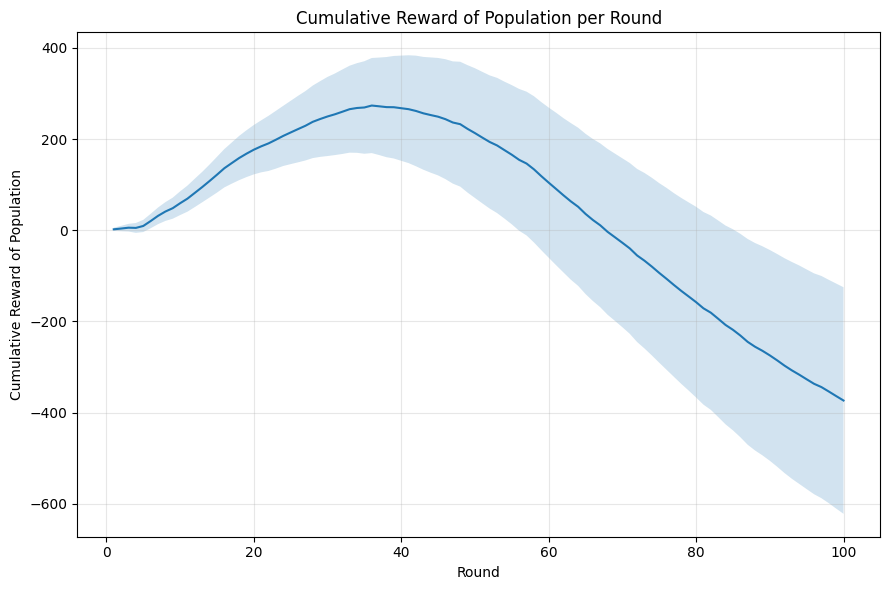

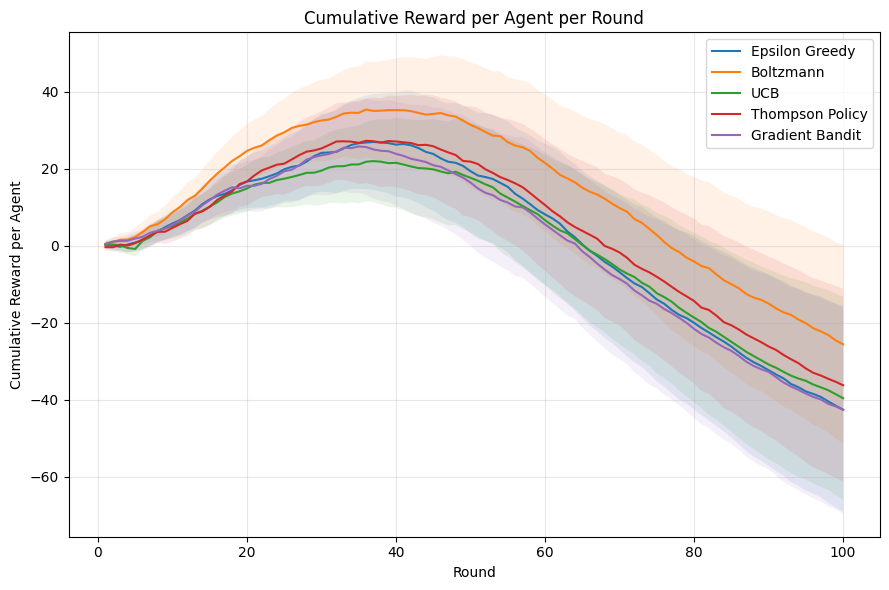

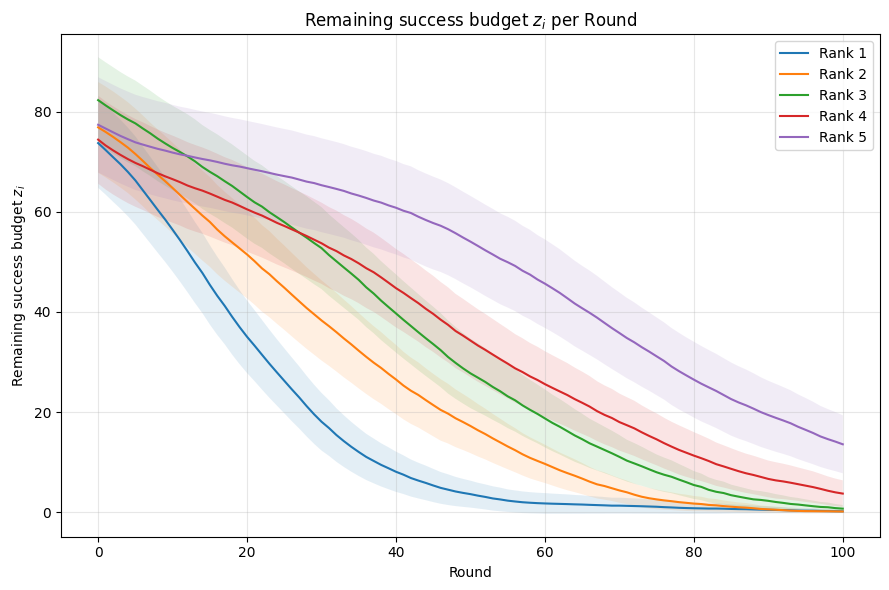

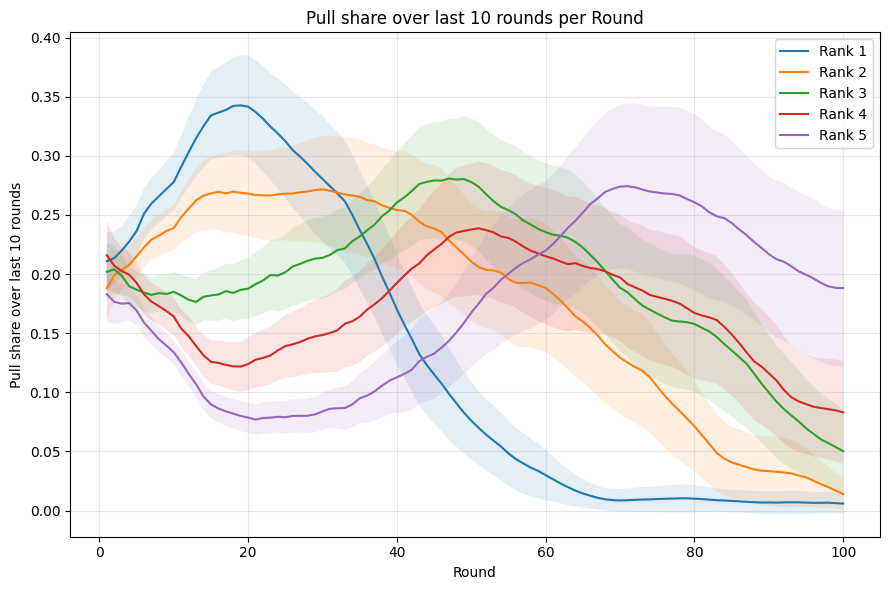

In [22]:
MIN_Z_I = 1
policies = []
for _ in range(2):
    policies.append(lambda: EpsilonGreedy(epsilon=eps, num_actions=NUM_ACTIONS))
    policies.append(lambda: Boltzmann(temperature=tau, num_actions=NUM_ACTIONS))
    policies.append(lambda: UCB(c=MAX_REWARD_ABS_VAL, num_actions=NUM_ACTIONS))
    policies.append(lambda: Thompson(num_actions=NUM_ACTIONS))
    policies.append(lambda: GradientBandit(alpha=alpha, num_actions=NUM_ACTIONS))

z_res = run_and_report(policies)
MIN_Z_I = 0.8

The results mostly support these expectations.

## $p_i \sim U\{0.05,0.8\}$

I expect greater variability across runs because the range of success probabilities is wider. Some actions also become more predictable, which may help agents identify their expected values more quickly. Therefore, I initially expect cumulative reward to increase.

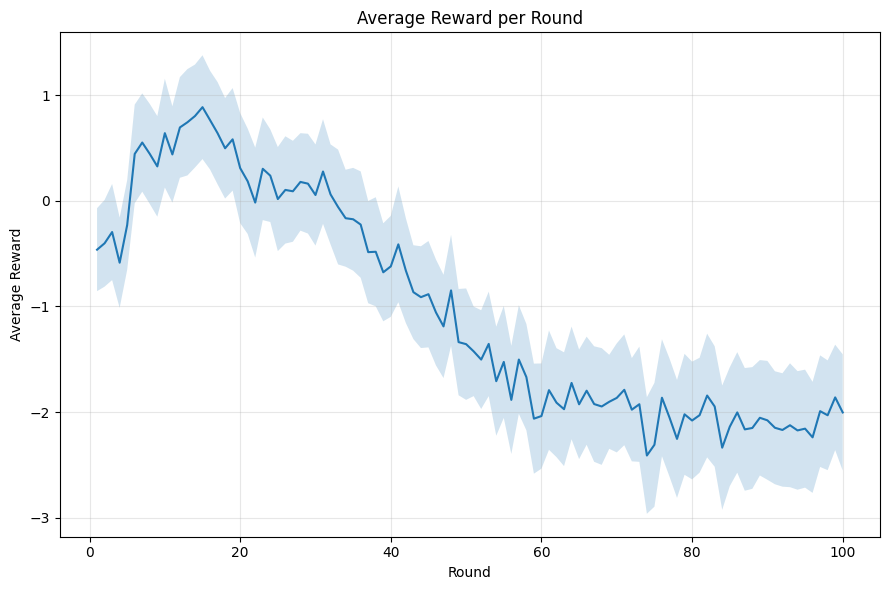

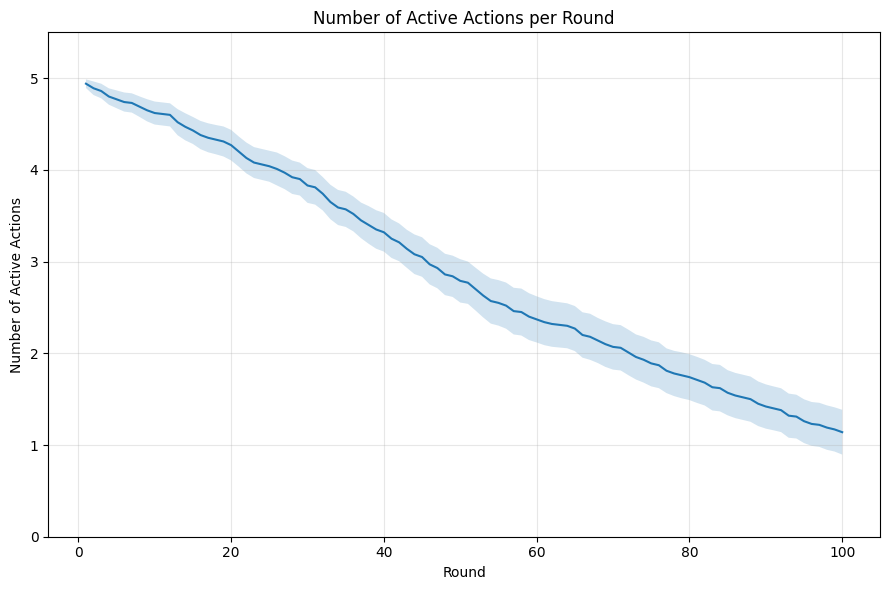

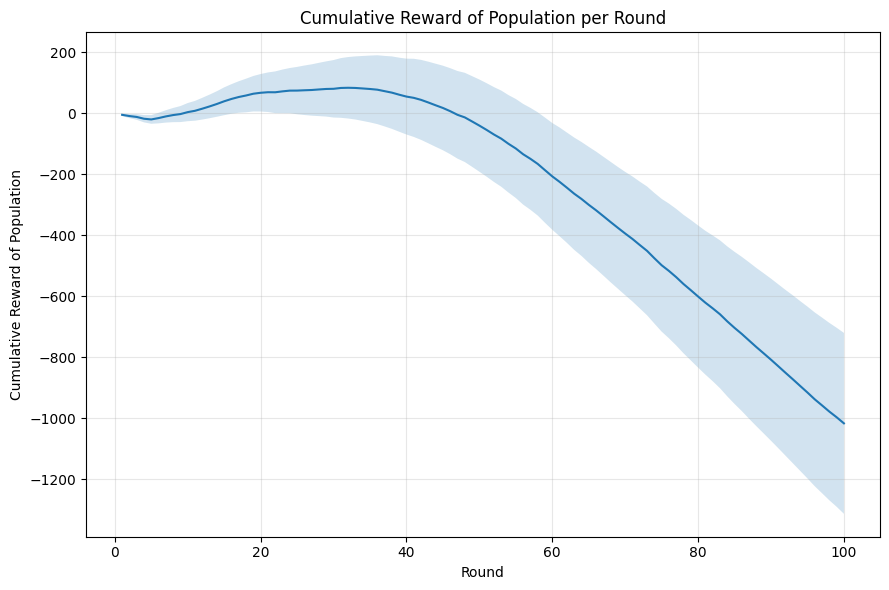

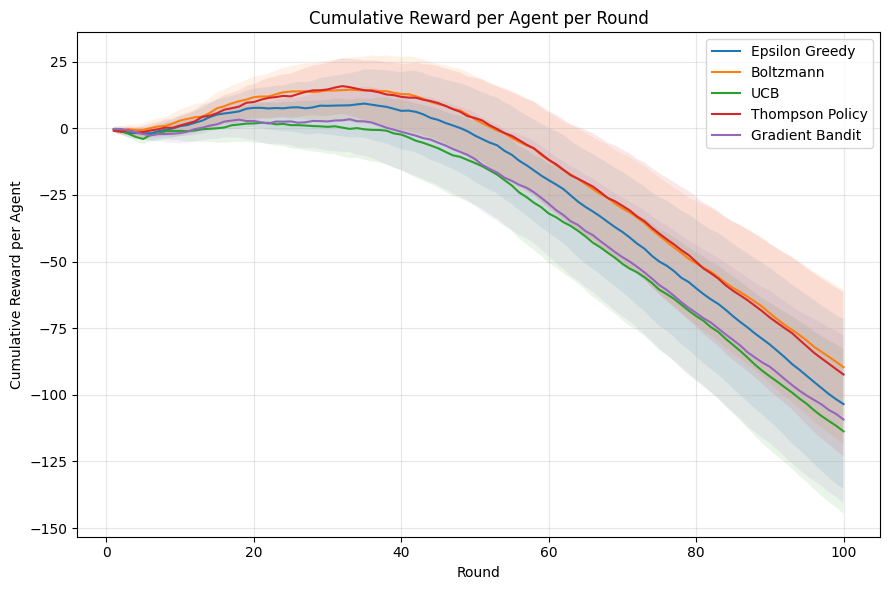

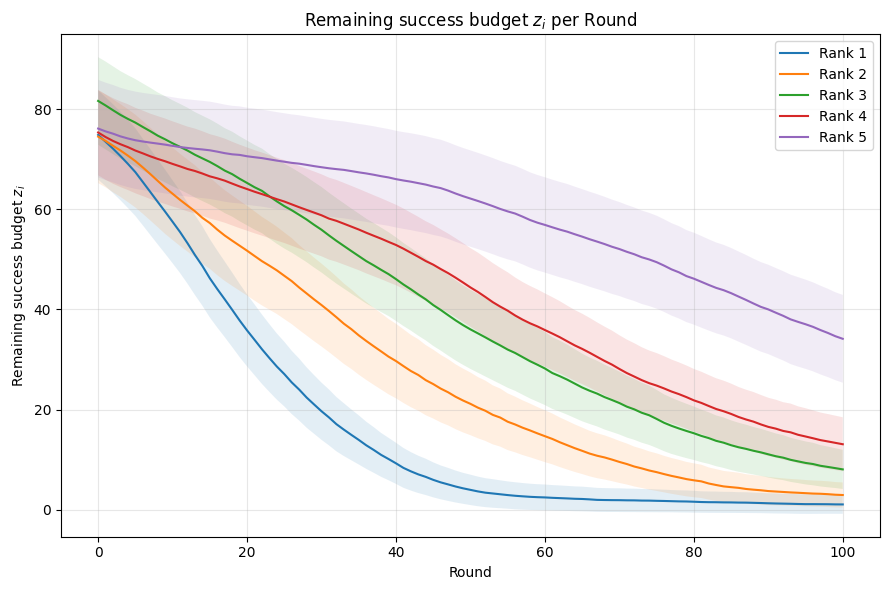

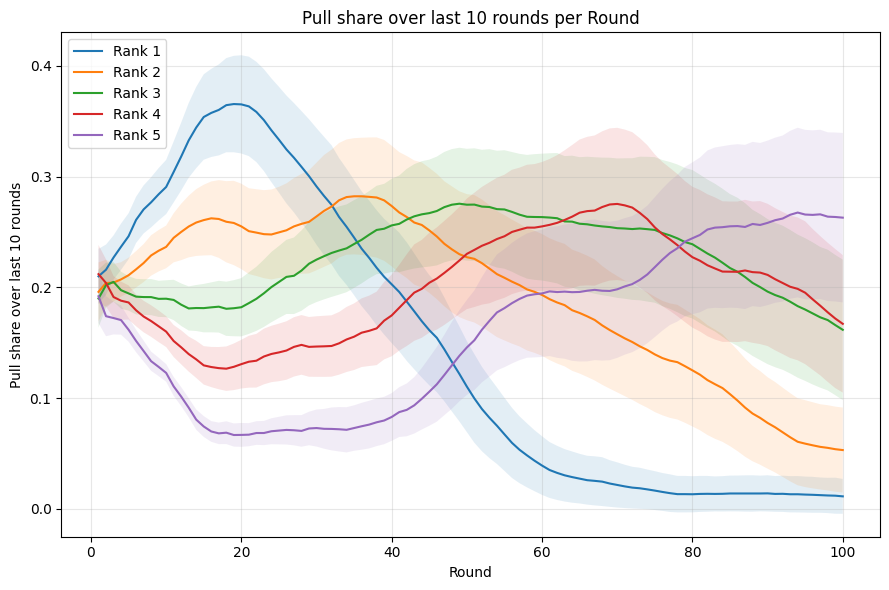

In [23]:
MIN_P_I = 0.05
policies = []
for _ in range(2):
    policies.append(lambda: EpsilonGreedy(epsilon=eps, num_actions=NUM_ACTIONS))
    policies.append(lambda: Boltzmann(temperature=tau, num_actions=NUM_ACTIONS))
    policies.append(lambda: UCB(c=MAX_REWARD_ABS_VAL, num_actions=NUM_ACTIONS))
    policies.append(lambda: Thompson(num_actions=NUM_ACTIONS))
    policies.append(lambda: GradientBandit(alpha=alpha, num_actions=NUM_ACTIONS))

p_res = run_and_report(policies)
MIN_P_I = 0.2

However, the cumulative reward is considerably lower than expected. One possible explanation is that actions with low expected rewards are still selected frequently. Since these actions have a lower probability of producing positive rewards, their selection can substantially reduce the total reward accumulated by the population.